In [1]:
import csv
from collections import Counter
import time
import pickle
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.linear_model import SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score,cross_validate,GroupKFold
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize
from sklearn.inspection import partial_dependence, PartialDependenceDisplay


from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)


In [2]:
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

TRAIN_PATH = "data/train.csv"
TEST_PATH = "data/test.csv"

In [3]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("HAR_MiniBatch_SGD_Binary")

/home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_2/notebook/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1779135563507, experiment_id='1', last_update_time=1779135563507, lifecycle_stage='active', name='HAR_MiniBatch_SGD_Binary', tags={}, trace_location=None, workspace='default'>

### Explanation
Before loading the CSV into pandas, I inspect the raw header row to detect whether duplicate feature names exist. This is necessary because pandas may automatically modify duplicate names during import, which would hide the original issue.

In [4]:
# Read only the header row from the CSV file
# `next(csv.reader(file))` returns the first row, which contains column names
with open(TRAIN_PATH, "r", encoding="utf-8") as file:
    raw_columns = next(csv.reader(file))

# Count how many times each column name appears
column_counts = Counter(raw_columns)

# Keep only the columns that appear more than once
# This creates a dictionary:
# {
#     column_name: number_of_times_it_appears
# }
duplicate_name_groups = {
    column: count
    for column, count in column_counts.items()
    if count > 1
}
# Count how many UNIQUE column names are duplicated
num_duplicate_column_names = len(duplicate_name_groups)
# Count duplicate occurrences beyond the first appearance
num_duplicate_occurrences = sum(count - 1 for count in duplicate_name_groups.values())

print(f"Number of repeated column names: {num_duplicate_column_names}")
print(f"Number of duplicate column occurrences beyond the first: {num_duplicate_occurrences}")

# Show all duplicated column names and their frequencies
duplicate_name_groups

Number of repeated column names: 42
Number of duplicate column occurrences beyond the first: 84


{'fBodyAcc-bandsEnergy()-1,8': 3,
 'fBodyAcc-bandsEnergy()-9,16': 3,
 'fBodyAcc-bandsEnergy()-17,24': 3,
 'fBodyAcc-bandsEnergy()-25,32': 3,
 'fBodyAcc-bandsEnergy()-33,40': 3,
 'fBodyAcc-bandsEnergy()-41,48': 3,
 'fBodyAcc-bandsEnergy()-49,56': 3,
 'fBodyAcc-bandsEnergy()-57,64': 3,
 'fBodyAcc-bandsEnergy()-1,16': 3,
 'fBodyAcc-bandsEnergy()-17,32': 3,
 'fBodyAcc-bandsEnergy()-33,48': 3,
 'fBodyAcc-bandsEnergy()-49,64': 3,
 'fBodyAcc-bandsEnergy()-1,24': 3,
 'fBodyAcc-bandsEnergy()-25,48': 3,
 'fBodyAccJerk-bandsEnergy()-1,8': 3,
 'fBodyAccJerk-bandsEnergy()-9,16': 3,
 'fBodyAccJerk-bandsEnergy()-17,24': 3,
 'fBodyAccJerk-bandsEnergy()-25,32': 3,
 'fBodyAccJerk-bandsEnergy()-33,40': 3,
 'fBodyAccJerk-bandsEnergy()-41,48': 3,
 'fBodyAccJerk-bandsEnergy()-49,56': 3,
 'fBodyAccJerk-bandsEnergy()-57,64': 3,
 'fBodyAccJerk-bandsEnergy()-1,16': 3,
 'fBodyAccJerk-bandsEnergy()-17,32': 3,
 'fBodyAccJerk-bandsEnergy()-33,48': 3,
 'fBodyAccJerk-bandsEnergy()-49,64': 3,
 'fBodyAccJerk-bandsEnerg

In [5]:
def make_column_names_unique(columns):
    seen = {}
    unique_columns = []

    for column in columns:
        if column not in seen:
            seen[column] = 0
            unique_columns.append(column)
        else:
            seen[column] += 1
            unique_columns.append(f"{column}_{seen[column]}")

    return unique_columns

In [6]:
train_df = pd.read_csv(TRAIN_PATH)

# Replace pandas' automatically interpreted headers with our controlled unique headers
train_df.columns = make_column_names_unique(raw_columns)

train_df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


In [7]:
train_df.columns.values

array(['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z',
       'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
       'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z',
       'tBodyAcc-max()-X', 'tBodyAcc-max()-Y', 'tBodyAcc-max()-Z',
       'tBodyAcc-min()-X', 'tBodyAcc-min()-Y', 'tBodyAcc-min()-Z',
       'tBodyAcc-sma()', 'tBodyAcc-energy()-X', 'tBodyAcc-energy()-Y',
       'tBodyAcc-energy()-Z', 'tBodyAcc-iqr()-X', 'tBodyAcc-iqr()-Y',
       'tBodyAcc-iqr()-Z', 'tBodyAcc-entropy()-X', 'tBodyAcc-entropy()-Y',
       'tBodyAcc-entropy()-Z', 'tBodyAcc-arCoeff()-X,1',
       'tBodyAcc-arCoeff()-X,2', 'tBodyAcc-arCoeff()-X,3',
       'tBodyAcc-arCoeff()-X,4', 'tBodyAcc-arCoeff()-Y,1',
       'tBodyAcc-arCoeff()-Y,2', 'tBodyAcc-arCoeff()-Y,3',
       'tBodyAcc-arCoeff()-Y,4', 'tBodyAcc-arCoeff()-Z,1',
       'tBodyAcc-arCoeff()-Z,2', 'tBodyAcc-arCoeff()-Z,3',
       'tBodyAcc-arCoeff()-Z,4', 'tBodyAcc-correlation()-X,Y',
       'tBodyAcc-correlation()-

In [8]:
train_df['fBodyAcc-bandsEnergy()-1,8_1']

0      -0.999657
1      -0.999417
2      -0.999006
3      -0.999719
4      -0.999564
          ...   
7347   -0.329720
7348   -0.370166
7349   -0.508772
7350   -0.522315
7351   -0.473807
Name: fBodyAcc-bandsEnergy()-1,8_1, Length: 7352, dtype: float64

In [9]:
train_df['fBodyAcc-bandsEnergy()-1,8']

0      -0.999963
1      -0.999996
2      -0.999989
3      -0.999989
4      -0.999994
          ...   
7347   -0.684177
7348   -0.726986
7349   -0.655263
7350   -0.643425
7351   -0.709495
Name: fBodyAcc-bandsEnergy()-1,8, Length: 7352, dtype: float64

In [10]:
train_shape = train_df.shape
total_null_values = train_df.isna().sum().sum()
print(f"Train dataset shape: {train_shape}")
print(f"Total null values: {total_null_values}")

Train dataset shape: (7352, 563)
Total null values: 0


### 1.1 - Load and Inspect
The training dataset contains **7352 rows** and **563 columns** in total: 561 sensor-derived feature columns, one `subject` column, and one `Activity` target column.
The dataset contains **0 missing values**.
Before resolving column names, I found **84 duplicate column occurrences**. I kept the first instance of each name unchanged and appended numeric suffixes to later occurrences.

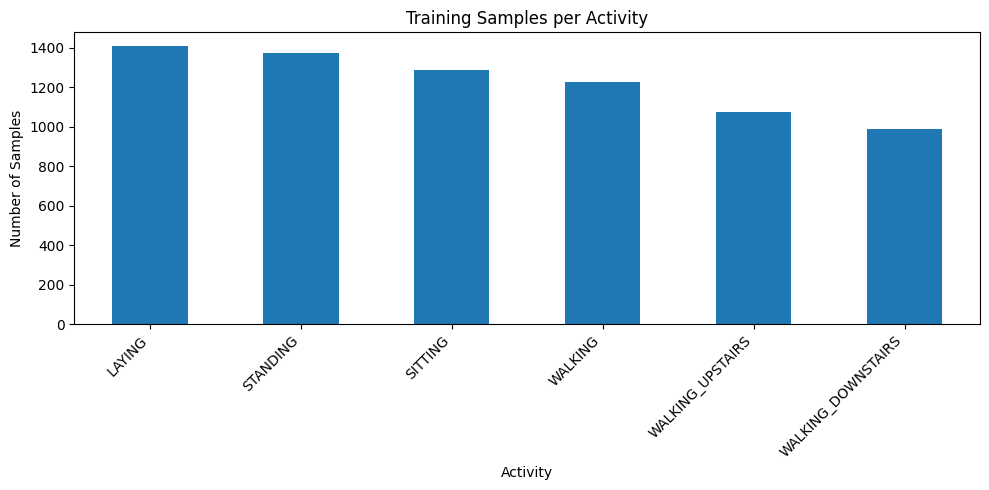

In [11]:
activity_counts = train_df["Activity"].value_counts()

plt.figure(figsize=(10, 5))
activity_counts.plot(kind="bar")
plt.title("Training Samples per Activity")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [12]:
activity_percentages = ( activity_counts / activity_counts.sum() ) * 100
activity_summary = pd.DataFrame({
    "Count": activity_counts,
    "Percentage": activity_percentages.round(2)
})

activity_summary

,Count,Percentage
Activity,,
LAYING,1407,19.14
STANDING,1374,18.69
SITTING,1286,17.49
WALKING,1226,16.68
WALKING_UPSTAIRS,1073,14.59
WALKING_DOWNSTAIRS,986,13.41


In [13]:
largest_class_count = activity_counts.max()
smallest_class_count = activity_counts.min()
imbalance_ratio = largest_class_count / smallest_class_count
print(f"Largest class count: {largest_class_count}")
print(f"Smallest class count: {smallest_class_count}")
print(f"Imbalance ratio: {imbalance_ratio:.3f}")

Largest class count: 1407
Smallest class count: 986
Imbalance ratio: 1.427


In [14]:
test_df = pd.read_csv(TEST_PATH)
test_df.columns = make_column_names_unique(raw_columns)
test_df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.257178,-0.023285,-0.014654,-0.938404,-0.920091,-0.667683,-0.952501,-0.925249,-0.674302,-0.894088,...,-0.705974,0.006462,0.162920,-0.825886,0.271151,-0.720009,0.276801,-0.057978,2,STANDING
1,0.286027,-0.013163,-0.119083,-0.975415,-0.967458,-0.944958,-0.986799,-0.968401,-0.945823,-0.894088,...,-0.594944,-0.083495,0.017500,-0.434375,0.920593,-0.698091,0.281343,-0.083898,2,STANDING
2,0.275485,-0.026050,-0.118152,-0.993819,-0.969926,-0.962748,-0.994403,-0.970735,-0.963483,-0.939260,...,-0.640736,-0.034956,0.202302,0.064103,0.145068,-0.702771,0.280083,-0.079346,2,STANDING
3,0.270298,-0.032614,-0.117520,-0.994743,-0.973268,-0.967091,-0.995274,-0.974471,-0.968897,-0.938610,...,-0.736124,-0.017067,0.154438,0.340134,0.296407,-0.698954,0.284114,-0.077108,2,STANDING
4,0.274833,-0.027848,-0.129527,-0.993852,-0.967445,-0.978295,-0.994111,-0.965953,-0.977346,-0.938610,...,-0.846595,-0.002223,-0.040046,0.736715,-0.118545,-0.692245,0.290722,-0.073857,2,STANDING


In [15]:
majority_class_train = train_df["Activity"].value_counts().idxmax()
majority_class_train

'LAYING'

In [16]:
majority_baseline_accuracy = (
    test_df["Activity"] == majority_class_train
).mean()

print(f"Majority class in training set: {majority_class_train}")
print(f"Majority-class baseline accuracy on test set: {majority_baseline_accuracy:.4f}")
print(f"Majority-class baseline accuracy on test set: {majority_baseline_accuracy * 100:.2f}%")

Majority class in training set: LAYING
Majority-class baseline accuracy on test set: 0.1822
Majority-class baseline accuracy on test set: 18.22%


### 1.2 - Activity Distribution
The training activity classes are fairly close in size, although they are not perfectly balanced. The largest class contains **1407** samples(19.14%), while the smallest class contains **986(13,41%)**, giving an imbalance ratio of **1.427**. The majority class in the training data is **LAYING**. If I predicted only this activity for every sample in the test set, the accuracy would be **18.22%**. 

In [17]:
time_mean_feature = "tGravityAcc-mean()-Z"
frequency_energy_feature = "fBodyGyro-energy()-Y"
jerk_magnitude_feature = "tBodyGyroJerkMag-mean()"
selected_features = [
    time_mean_feature,
    frequency_energy_feature,
    jerk_magnitude_feature
]

In [18]:
def plot_feature_by_activity(data, feature, title):
    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=data,
        x="Activity",
        y=feature
    )
    plt.title(title)
    plt.xlabel("Activity")
    plt.ylabel(feature)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

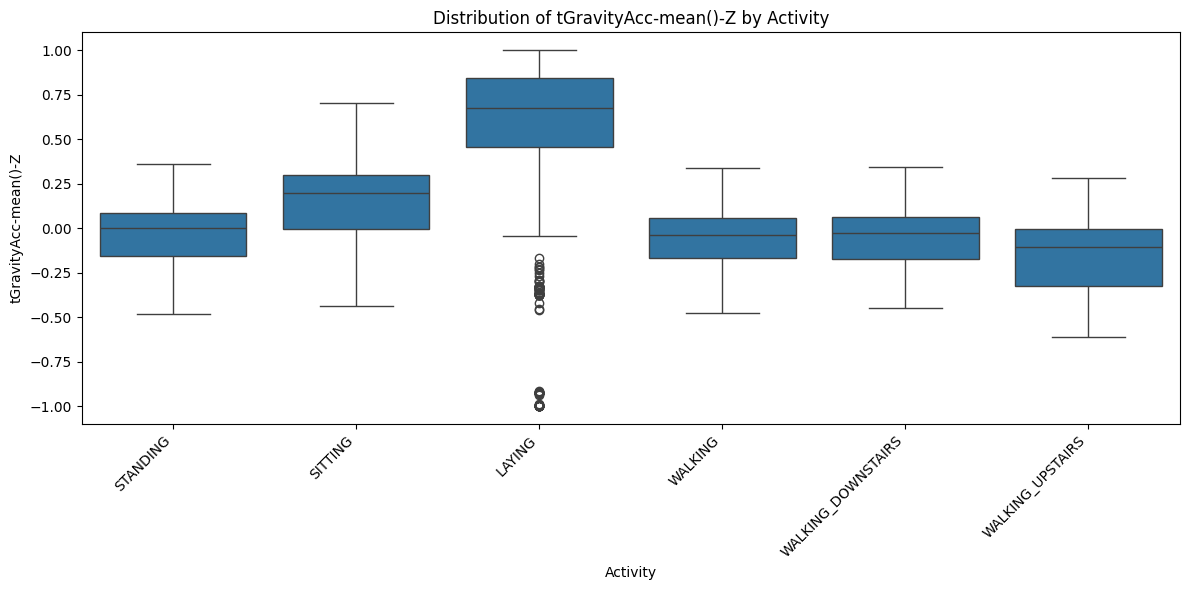

In [19]:
plot_feature_by_activity(
    train_df,
    time_mean_feature,
    "Distribution of tGravityAcc-mean()-Z by Activity"
)

### tGravityAcc-mean()-Z

`tGravityAcc-mean()-Z` is a time-domain mean feature computed from the gravity acceleration signal on the Z-axis. Gravity acceleration reflects the phone’s orientation relative to the body, so this feature is especially informative for posture-related activities.

The box plot shows that `LAYING` is the easiest activity to distinguish with this feature, because its values are centered much higher than the other activities. `SITTING` also tends to have higher values than most movement classes, although its distribution is wider and partially overlaps with others. The strongest overlap appears among `STANDING`, `WALKING`, and `WALKING_DOWNSTAIRS`, whose boxes are concentrated around similar values. Therefore, this feature is useful for detecting body orientation, but it cannot reliably separate several upright or movement-based activities on its own.

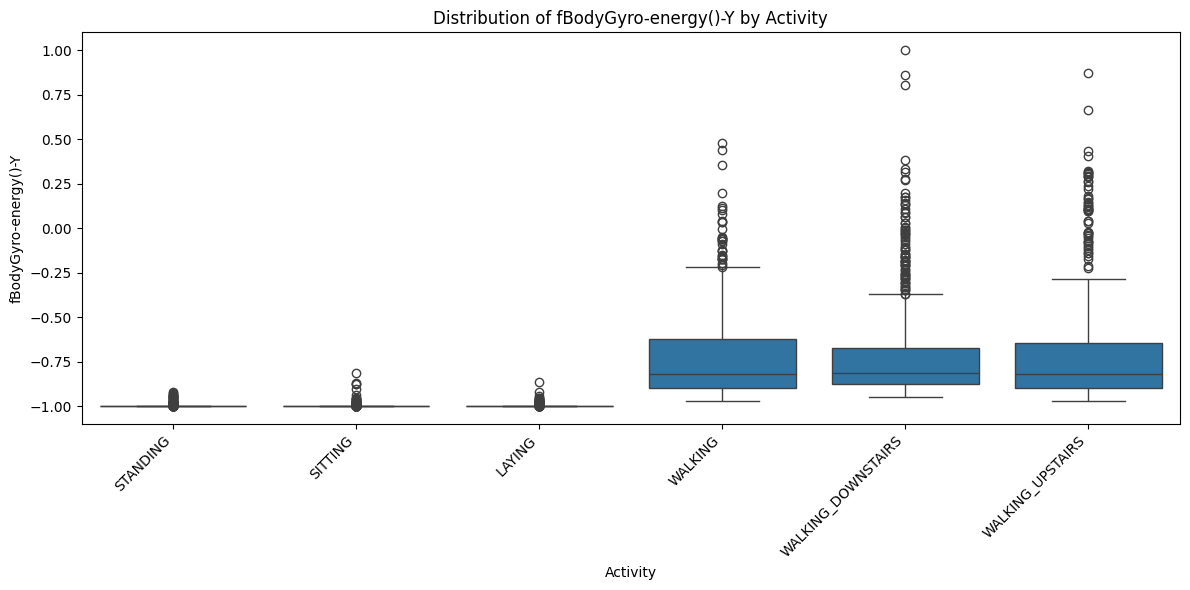

In [20]:
plot_feature_by_activity(
    train_df,
    frequency_energy_feature,
    "Distribution of fBodyGyro-energy()-Y by Activity"
)

### fBodyGyro-energy()-Y

`fBodyGyro-energy()-Y` is a frequency-domain energy feature derived from the gyroscope signal on the Y-axis. The raw rotational-motion signal is transformed into the frequency domain, and the energy feature summarizes the overall strength of oscillatory rotational movement within the time window.

This plot clearly separates the static activities from the dynamic ones. `STANDING`, `SITTING`, and `LAYING` are all tightly concentrated near the lowest values, showing that they contain very little rotational motion energy. In contrast, `WALKING`, `WALKING_DOWNSTAIRS`, and `WALKING_UPSTAIRS` have noticeably higher and more spread-out values, which is expected for movement activities. However, the three walking-related activities overlap strongly with one another, so this feature is much better for distinguishing “static vs. dynamic” behavior than for separating the individual walking classes.

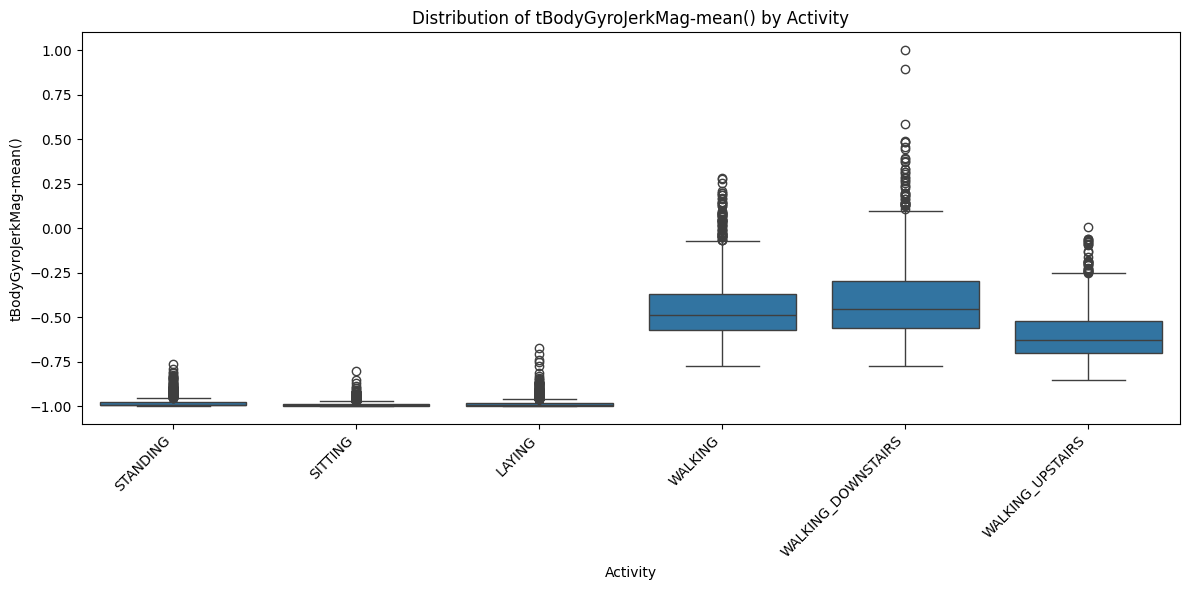

In [21]:
plot_feature_by_activity(
    train_df,
    jerk_magnitude_feature,
    "Distribution of tBodyGyroJerkMag-mean() by Activity"
)

### BodyGyroJerkMag-mean()

`tBodyGyroJerkMag-mean()` is a time-domain jerk magnitude feature. It is computed from the rate of change of the body gyroscope signal over time, then combined across axes into a single magnitude signal, and finally averaged within the observation window. It captures how abruptly rotational motion changes.

The plot again shows a very strong separation between static and dynamic activities. `STANDING`, `SITTING`, and `LAYING` are clustered close to the lowest values, meaning that their rotational motion changes are minimal. The dynamic activities have much higher values, reflecting stronger and more variable body motion. Among the moving classes, `WALKING` and `WALKING_DOWNSTAIRS` have highly overlapping distributions, making them difficult to distinguish using this single feature. `WALKING_UPSTAIRS` is somewhat lower on average, but it still overlaps with the other movement classes.

In [22]:
corr_df = train_df.copy()

In [23]:
dynamic_activities = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS"]
corr_df["DYNAMIC"] = corr_df["Activity"].isin(dynamic_activities).astype(int)

In [24]:
feature_cols = corr_df.select_dtypes(include="number").columns.drop(
    ["subject", "DYNAMIC"], errors="ignore"
)

In [25]:
feature_correlations = corr_df[feature_cols].corrwith(corr_df["DYNAMIC"])

In [26]:
absolute_correlations = feature_correlations.abs().sort_values(ascending=False)

In [27]:
top_20 = feature_correlations.loc[absolute_correlations.head(20).index].sort_values()
bottom_20 = feature_correlations.loc[absolute_correlations.tail(20).index].sort_values()

In [28]:
top_20

tBodyAccMag-sma()                0.941714
tGravityAccMag-sma()             0.941714
tGravityAccMag-mean()            0.941714
tBodyAcc-std()-Y                 0.942390
fBodyAcc-sma()                   0.943617
fBodyAcc-entropy()-Z             0.944097
tBodyAcc-sma()                   0.944688
fBodyAcc-mad()-Y                 0.944780
tBodyGyroJerk-entropy()-Z        0.946925
fBodyAccMag-entropy()            0.948607
fBodyAcc-entropy()-Y             0.952735
fBodyAccJerk-entropy()-Z         0.956419
tBodyAccJerk-entropy()-Y         0.961064
tBodyAccJerk-entropy()-Z         0.961269
fBodyBodyAccJerkMag-entropy()    0.964093
fBodyAcc-entropy()-X             0.966413
tBodyAccJerk-entropy()-X         0.967290
tBodyAccJerkMag-entropy()        0.968348
fBodyAccJerk-entropy()-Y         0.971997
fBodyAccJerk-entropy()-X         0.977311
dtype: float64

In [29]:
bottom_20

angle(tBodyAccJerkMean),gravityMean)   -0.022774
tBodyGyroJerk-mean()-Y                 -0.019349
fBodyGyro-skewness()-Z                 -0.019207
tBodyAcc-correlation()-X,Z             -0.011804
angle(tBodyGyroJerkMean,gravityMean)   -0.011677
angle(tBodyAccMean,gravity)            -0.007216
tBodyAccJerk-mean()-Z                  -0.006631
tGravityAcc-correlation()-Y,Z          -0.005444
angle(tBodyGyroMean,gravityMean)       -0.004972
tBodyGyro-mean()-X                     -0.003237
tBodyAccJerk-mean()-Y                   0.000626
tBodyGyroMag-arCoeff()4                 0.001060
tBodyAccJerk-arCoeff()-X,2              0.004979
tBodyGyroMag-arCoeff()2                 0.006048
tBodyGyro-mean()-Y                      0.007480
tBodyAcc-mean()-X                       0.008514
tBodyAccJerk-mean()-X                   0.010184
tBodyGyroJerk-mean()-X                  0.011734
tBodyGyroJerk-mean()-Z                  0.013145
tBodyGyro-correlation()-X,Y             0.018680
dtype: float64

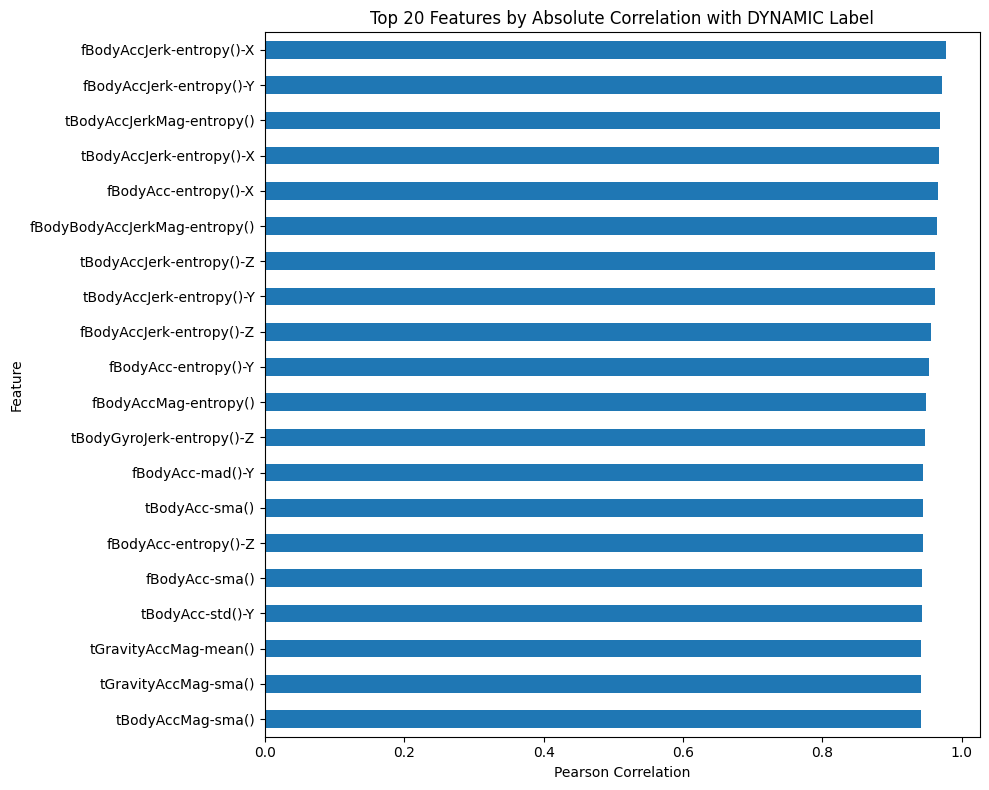

In [30]:
# Top 20 features by absolute correlation
plt.figure(figsize=(10, 8))
top_20.plot(kind="barh")
plt.title("Top 20 Features by Absolute Correlation with DYNAMIC Label")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

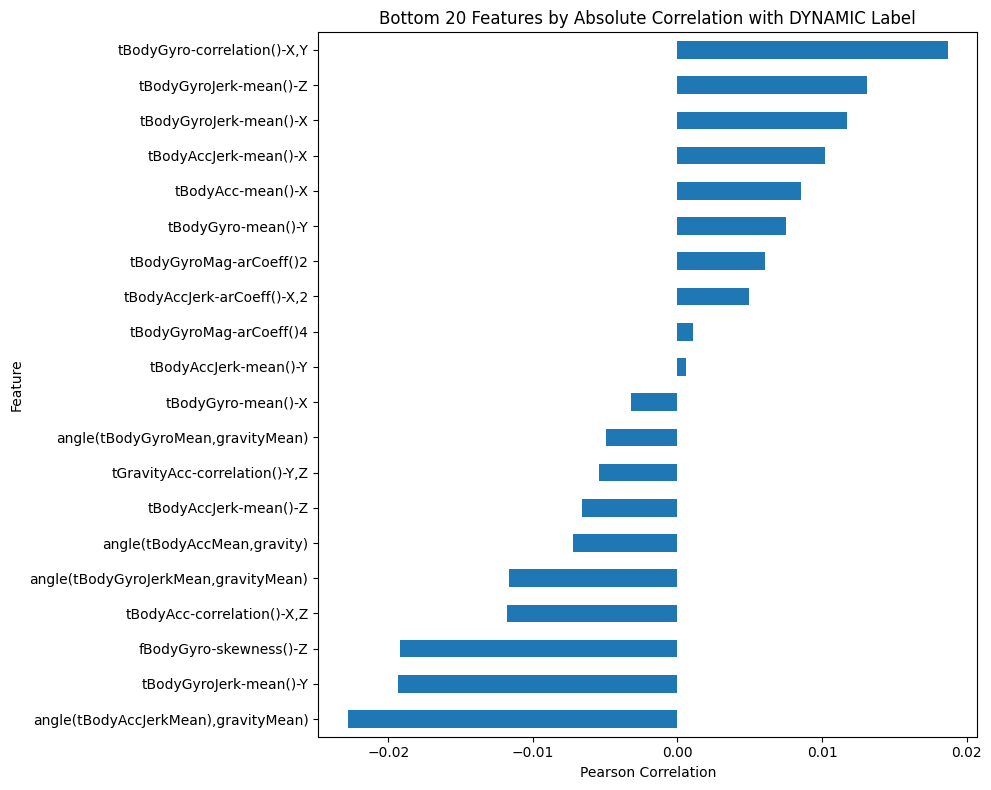

In [31]:
# Bottom 20 features by absolute correlation
plt.figure(figsize=(10, 8))
bottom_20.plot(kind="barh")
plt.title("Bottom 20 Features by Absolute Correlation with DYNAMIC Label")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Correlation Analysis

The features most strongly related to the `DYNAMIC` label are the ones that measure how much the body is moving and how much that movement changes. This is expected, because walking activities involve stronger and more irregular motion than sitting, standing, or laying.

The highest correlation is **0.977** for `fBodyAccJerk-entropy()-X`, which means this feature is very useful for telling dynamic and static activities apart.

The weakest features have correlations close to **0**, so they do not help much for this specific binary distinction. These are mostly simple average, angle, or axis-relationship features.
Overall, the analysis shows that **movement strength and movement variability** are the most useful signals for separating dynamic activities from static ones.

### 2 - PREPROCESSING

In [32]:
feature_cols = [
    col for col in train_df.columns
    if col not in ["subject", "Activity"]
]

In [33]:
X_train = train_df[feature_cols].copy()
y_train = train_df["Activity"].copy()

In [34]:
sampled_features = pd.Series(feature_cols).sample(
    n=5,
    random_state=RANDOM_SEED
).tolist()

scaling_check_table = pd.DataFrame({
    "Feature": sampled_features,
    "Min": X_train[sampled_features].min().values,
    "Max": X_train[sampled_features].max().values
})

scaling_check_table

,Feature,Min,Max
0,fBodyAccMag-skewness(),-1.0,1.0
1,"fBodyAcc-bandsEnergy()-1,24_2",-1.0,1.0
2,tBodyGyroJerk-energy()-Y,-1.0,1.0
3,tBodyAccJerk-mad()-X,-1.0,1.0
4,"fBodyAcc-bandsEnergy()-25,32_2",-1.0,1.0


In [35]:
X_test = test_df[feature_cols].copy()
y_test = test_df["Activity"].copy()

In [36]:
scaler = StandardScaler()

In [37]:
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

X_train_scaled.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.200642,-0.063683,-0.419628,-0.868814,-0.939441,-0.737529,-0.859817,-0.939019,-0.766437,-0.856036,...,-0.795359,0.025960,-0.276399,-0.360603,0.062940,-0.778427,-0.026080,-0.687219,0.407946,-0.007568
1,0.055948,0.031486,-0.253908,-0.875426,-0.923902,-0.849304,-0.868531,-0.921998,-0.848928,-0.871359,...,0.130614,-0.897357,-0.767990,0.133011,-0.021461,-1.218805,1.484470,-0.694138,0.409117,0.007875
2,0.073515,-0.043416,-0.076295,-0.869039,-0.907760,-0.893785,-0.863137,-0.898854,-0.896701,-0.863323,...,1.152336,-0.260878,-0.438316,-0.377840,0.391976,0.151207,1.704201,-0.702239,0.410288,0.026502
3,0.066696,-0.208422,-0.249712,-0.870626,-0.940022,-0.921805,-0.864503,-0.938124,-0.925279,-0.863323,...,1.112769,0.591045,0.463155,-0.135025,-0.033637,1.037851,-1.003019,-0.701684,0.414650,0.031714
4,0.030469,0.027587,-0.109848,-0.875188,-0.934878,-0.921343,-0.867384,-0.931789,-0.928028,-0.870260,...,-0.149577,-0.138515,-0.240313,0.340406,0.268486,1.125918,-1.276282,-0.700152,0.425463,0.045225


### Explanation for using Standard scaler
Both features share the same [-1, 1] range, but Feature A's values are clustered tightly while Feature B's are spread out. Because KNN/SVM rely on distances, Feature B will dominate the calculation — not because it matters more, but simply because it varies more. That is why we should scale them so every features should have mean=0 and variance=1.

In [38]:
variance_selector = VarianceThreshold(threshold=0.0)
variance_selector.fit(X_train)

num_original_features = X_train.shape[1]
num_features_after_variance_filter = variance_selector.get_support().sum()
num_zero_variance_features = num_original_features - num_features_after_variance_filter

print(f"Original number of features: {num_original_features}")
print(f"Zero-variance features: {num_zero_variance_features}")

Original number of features: 561
Zero-variance features: 0


In [39]:
# 2. Count feature pairs with Pearson |r| > 0.95
corr_matrix = X_train.corr().abs()

# Keep only the upper triangle so each pair is counted once
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

num_high_corr_pairs = (upper_triangle > 0.95).sum().sum()

print(f"Number of feature pairs with |r| > 0.95: {num_high_corr_pairs}")

Number of feature pairs with |r| > 0.95: 2281


In [40]:
high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
    .rename(columns={
        "level_0": "Feature 1",
        "level_1": "Feature 2",
        0: "Absolute Pearson Correlation"
    })
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Absolute Pearson Correlation"] > 0.95
].sort_values(
    by="Absolute Pearson Correlation",
    ascending=False
)

high_corr_pairs.head(20)

,Feature 1,Feature 2,Absolute Pearson Correlation
156556,fBodyBodyGyroMag-mean(),fBodyBodyGyroMag-sma(),1.0
155373,fBodyAccMag-mean(),fBodyAccMag-sma(),1.0
105403,tBodyGyroMag-mean(),tBodyGyroMag-sma(),1.0
109498,tBodyGyroJerkMag-mean(),tBodyGyroJerkMag-sma(),1.0
95667,tBodyAccMag-arCoeff()2,tGravityAccMag-arCoeff()2,1.0
95316,tBodyAccMag-arCoeff()1,tGravityAccMag-arCoeff()1,1.0
92472,tBodyAccMag-std(),tGravityAccMag-std(),1.0
92104,tBodyAccMag-mean(),tBodyAccMag-sma(),1.0
156049,fBodyBodyAccJerkMag-mean(),fBodyBodyAccJerkMag-sma(),1.0
156894,fBodyBodyGyroJerkMag-mean(),fBodyBodyGyroJerkMag-sma(),1.0


### Dimensionality Assessment

The dataset contains **561 input features**, and applying `VarianceThreshold(threshold=0.0)` showed that there are **0 zero-variance features**. This means every feature changes across the training samples and none can be removed for being completely constant.

However, the correlation analysis reveals substantial redundancy in the feature space. There are **2281 feature pairs** with absolute Pearson correlation greater than **0.95**, which indicates that many features contain very similar information. Some pairs even have a perfect correlation of **1.0**, meaning they behave identically across the training set.

Because there are no zero-variance features, I will not remove any columns using `VarianceThreshold`. For **tree-based models**, I will keep the full feature set, since models such as Decision Trees and Random Forests can work well even when predictors are highly correlated. For **distance-based models**, such as **KNN** and **SVM**, feature reduction may be beneficial because the dataset contains many strongly correlated features. Reducing redundant information can make these models more efficient and may improve how distances or decision boundaries are learned.

In [41]:
train_subjects = set(train_df["subject"].unique())
test_subjects = set(test_df["subject"].unique())

subject_intersection = train_subjects.intersection(test_subjects)

print(f"Subjects appearing in both splits: {sorted(subject_intersection)}")
print(f"Number of subjects appearing in both splits: {len(subject_intersection)}")

Subjects appearing in both splits: []
Number of subjects appearing in both splits: 0


### 2.3 - Subject Independence
There is **no subject overlap** between the training and test sets. This matters because the model should be evaluated on people it has never seen before, not on new samples from the same people it learned from during training. If the same subject appeared in both splits, the model could partially learn person-specific movement patterns, which would make test performance look better than real-world generalization.

In [42]:
## Concat train_df and test_df
df = pd.concat([train_df, test_df], ignore_index=True)

print(df.shape)
print(df["subject"].nunique())

(10299, 563)
30


In [43]:
all_subjects = df["subject"].unique()

In [44]:
df

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10294,0.310155,-0.053391,-0.099109,-0.287866,-0.140589,-0.215088,-0.356083,-0.148775,-0.232057,0.185361,...,-0.750809,-0.337422,0.346295,0.884904,-0.698885,-0.651732,0.274627,0.184784,24,WALKING_UPSTAIRS
10295,0.363385,-0.039214,-0.105915,-0.305388,0.028148,-0.196373,-0.373540,-0.030036,-0.270237,0.185361,...,-0.700274,-0.736701,-0.372889,-0.657421,0.322549,-0.655181,0.273578,0.182412,24,WALKING_UPSTAIRS
10296,0.349966,0.030077,-0.115788,-0.329638,-0.042143,-0.250181,-0.388017,-0.133257,-0.347029,0.007471,...,-0.467179,-0.181560,0.088574,0.696663,0.363139,-0.655357,0.274479,0.181184,24,WALKING_UPSTAIRS
10297,0.237594,0.018467,-0.096499,-0.323114,-0.229775,-0.207574,-0.392380,-0.279610,-0.289477,0.007471,...,-0.617737,0.444558,-0.819188,0.929294,-0.008398,-0.659719,0.264782,0.187563,24,WALKING_UPSTAIRS


In [45]:
expected_activities = set(df["Activity"].unique())

In [46]:
max_tries = 100

In [47]:
# Repeat until both train and test contain all 6 activities
for attempt in range(max_tries):
    train_subject_ids, test_subject_ids = train_test_split(
        all_subjects,
        train_size=0.70,
        random_state=RANDOM_SEED + attempt,
        shuffle=True
    )

    train_split_df = df[df["subject"].isin(train_subject_ids)].copy()
    test_split_df = df[df["subject"].isin(test_subject_ids)].copy()

    train_activities = set(train_split_df["Activity"].unique())
    test_activities = set(test_split_df["Activity"].unique())

    if train_activities == expected_activities and test_activities == expected_activities:
        break

In [48]:
feature_cols = [
    col for col in df.columns
    if col not in ["subject", "Activity"]
]

X_train_subject_split = train_split_df[feature_cols].copy()
X_test_subject_split = test_split_df[feature_cols].copy()

y_train_subject_split = train_split_df["Activity"].copy()
y_test_subject_split = test_split_df["Activity"].copy()

In [49]:
train_subject_set = set(train_split_df["subject"].unique())
test_subject_set = set(test_split_df["subject"].unique())
split_intersection = train_subject_set.intersection(test_subject_set)

print(f"Intersection: {sorted(split_intersection)}")
print(f"Subject overlap exists: {len(split_intersection) > 0}")

print(f"\nTrain split shape: {X_train_subject_split.shape}")
print(f"Test split shape: {X_test_subject_split.shape}")

print(f"\nTrain activities: {sorted(y_train_subject_split.unique())}")
print(f"Test activities: {sorted(y_test_subject_split.unique())}")

Intersection: []
Subject overlap exists: False

Train split shape: (7112, 561)
Test split shape: (3187, 561)

Train activities: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
Test activities: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']


### Task 3 - Unsupervised Exploration

In [50]:
pca_full = PCA()
X_train_pca_full = pca_full.fit_transform(X_train_scaled)

In [51]:
# Cumulative explained variance
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

In [52]:
# How many PCA components do we need to keep at least 95% of the dataset’s total variation?
# Number of components needed for 95% variance
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print(f"Number of PCA components needed to retain 95% variance: {n_components_95}")

Number of PCA components needed to retain 95% variance: 102


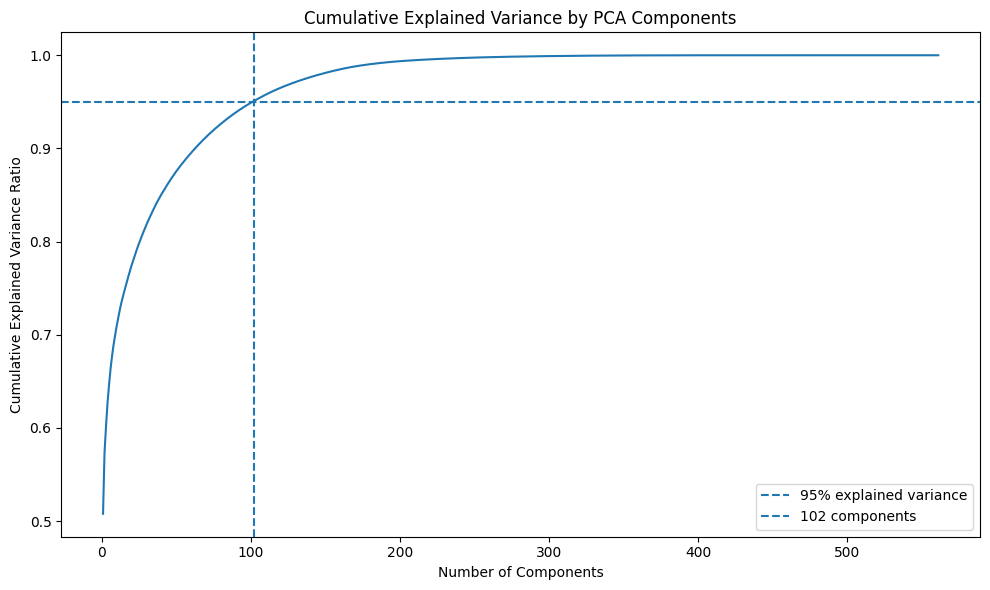

In [53]:
plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(y=0.95, linestyle="--", label="95% explained variance")
plt.axvline(x=n_components_95, linestyle="--", label=f"{n_components_95} components")

plt.title("Cumulative Explained Variance by PCA Components")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
# 2D PCA projection
pca_2d = PCA(n_components=2)
X_train_pca_2d = pca_2d.fit_transform(X_train_scaled)

pca_2d_df = pd.DataFrame({
    "PC1": X_train_pca_2d[:, 0],
    "PC2": X_train_pca_2d[:, 1],
    "Activity": y_train.values
})

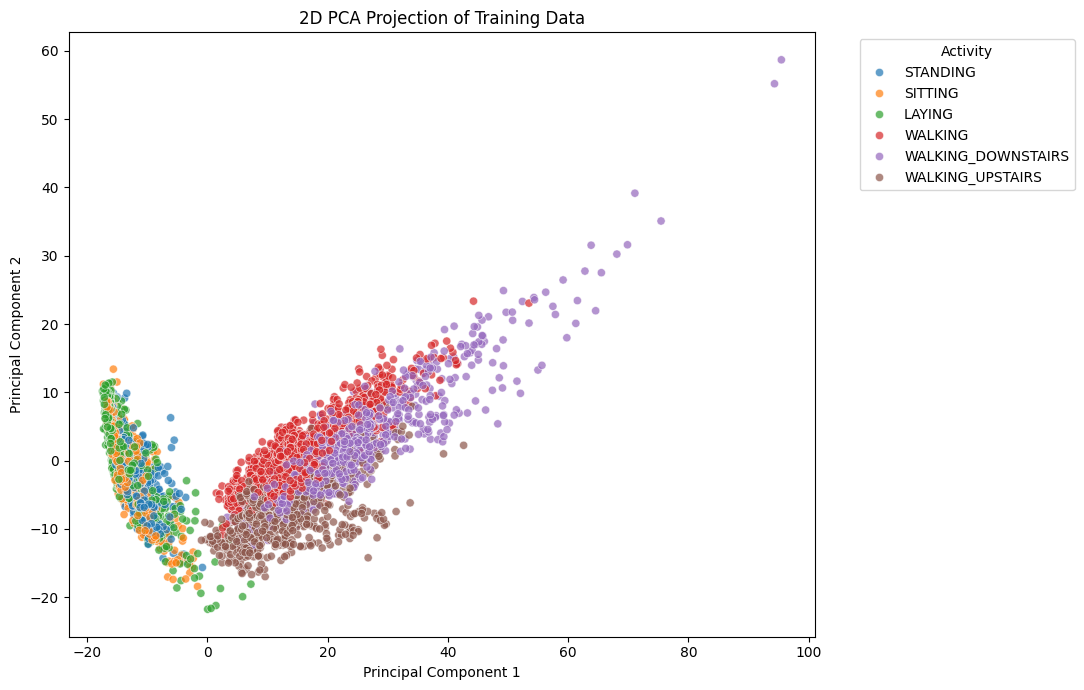

In [55]:
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=pca_2d_df,
    x="PC1",
    y="PC2",
    hue="Activity",
    alpha=0.7,
    s=35
)

plt.title("2D PCA Projection of Training Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Activity", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

### PCA 2D Projection

The 2D PCA plot shows a general separation between **static activities** and **dynamic activities**. `STANDING`, `SITTING`, and `LAYING` are mostly grouped on the left side, while `WALKING`, `WALKING_DOWNSTAIRS`, and `WALKING_UPSTAIRS` are mainly on the right side.
However, the classes are not perfectly separated. The static activities overlap quite a lot with each other, especially `STANDING` and `SITTING`. Overall, PCA captures the broad difference between static and moving activities, but it does not clearly separate all six classes in only two dimensions. This is expected because reducing 561 features to just 2 components loses a lot of detailed information.

In [56]:
# Retain the 50-component PCA representation for t-SNE
pca_50 = PCA(n_components=50)
X_train_pca_50 = pca_50.fit_transform(X_train_scaled)

print(f"PCA-50 shape: {X_train_pca_50.shape}")
print(f"Variance retained by 50 PCA components: {pca_50.explained_variance_ratio_.sum():.4f}")

PCA-50 shape: (7352, 50)
Variance retained by 50 PCA components: 0.8752


In [57]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    max_iter=1000,
    random_state=RANDOM_SEED,
    init="pca",
    learning_rate="auto"
)

X_train_tsne = tsne.fit_transform(X_train_pca_50)

In [58]:
tsne_df = pd.DataFrame({
    "t-SNE 1": X_train_tsne[:, 0],
    "t-SNE 2": X_train_tsne[:, 1],
    "Activity": y_train.values
})

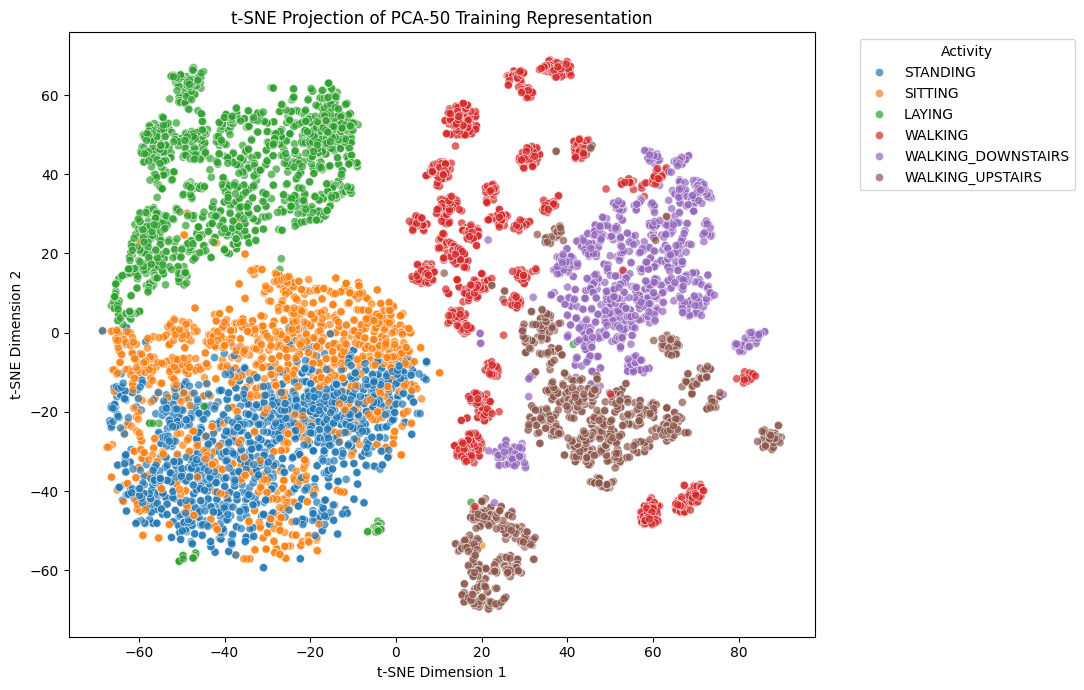

In [59]:
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=tsne_df,
    x="t-SNE 1",
    y="t-SNE 2",
    hue="Activity",
    alpha=0.7,
    s=35
)

plt.title("t-SNE Projection of PCA-50 Training Representation")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Activity", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 3.2 - t-SNE

The t-SNE plot shows that `LAYING` forms the clearest separate cluster. Most of the dynamic activities are also mostly grouped away from the static ones, which means their overall movement patterns are different. The biggest overlap is between `SITTING` and `STANDING`, so these two seem hardest to separate. Some overlap also exists between the walking-related activities like `WALKING_DOWNSTAIRS` and `WALKING_UPSTAIRS`. This matches what I saw in Task 1.3: `LAYING` was easier to distinguish, static and dynamic activities were generally different, and similar activities such as `SITTING` vs. `STANDING` or the walking classes were harder to separate using only one feature.

In [60]:
k_values = range(2, 13)

inertias = [] # Within-cluster sum of squares (Elbow Method)
silhouette_scores = [] # Cluster separation quality

# Train a KMeans model for each value of k
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_SEED,
        n_init=20 # Run KMeans 20 times with different centroid seeds
    )
    
    cluster_labels = kmeans.fit_predict(X_train_pca_50)
    
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_train_pca_50, cluster_labels)
    )

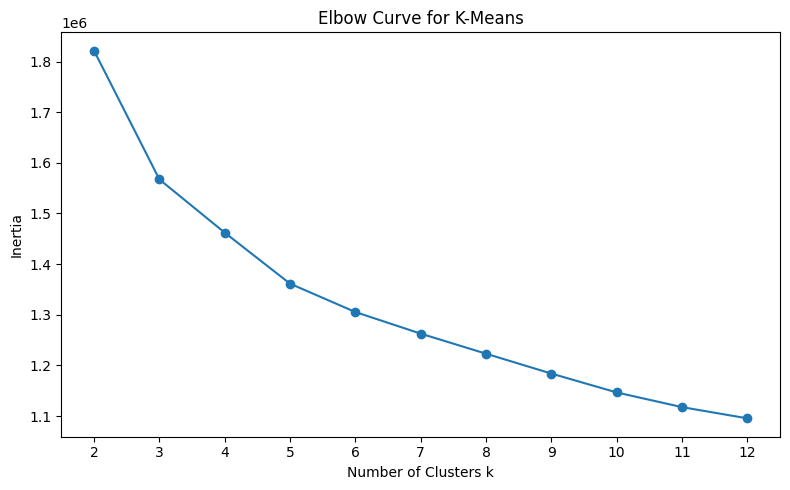

In [61]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertias, marker="o")

plt.title("Elbow Curve for K-Means")
plt.xlabel("Number of Clusters k")
plt.ylabel("Inertia")

# Show every tested k value on the x-axis
plt.xticks(list(k_values))

plt.tight_layout()
plt.show()

The elbow curve shows how the K-Means error, called inertia, decreases as we allow more clusters. A lower inertia means that points are closer to the center of their assigned cluster, so the clustering fits the data better. Here, inertia drops a lot from k = 2 to k = 3, and it continues decreasing until around k = 5. After that, as we add more clusters the we are not getting bigger improvements. But the plot suggests that around 3 to 5 clusters may describe the structure reasonably well.

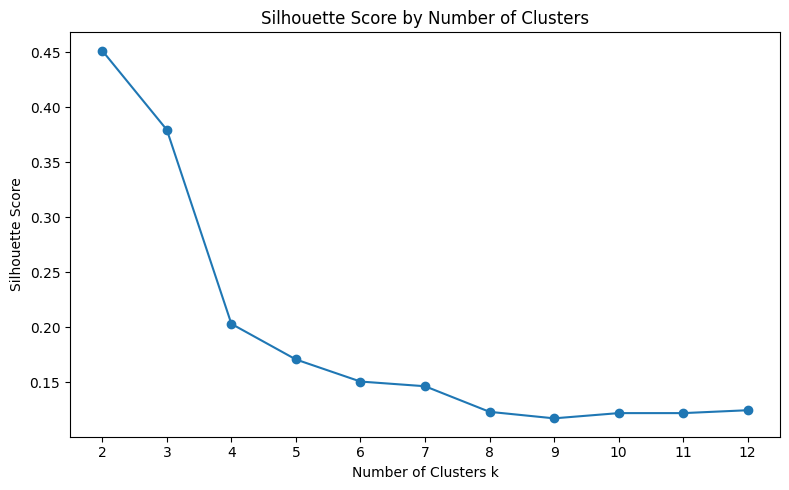

In [62]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_scores, marker="o")

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters k")
plt.ylabel("Silhouette Score")

# Show every tested k value on the x-axis
plt.xticks(list(k_values))

plt.tight_layout()
plt.show()

The silhouette score is highest at **k = 2**, which suggests that the data is most naturally separated into two broad clusters. These two clusters likely represent **static activities** and **dynamic activities**, which matches the patterns from before. As `k` increases toward 6, the silhouette score becomes much lower, meaning the individual activity classes are not cleanly separated by K-Means clustering alone.

In [63]:
# Fit K-Means with k = 6
kmeans_6 = KMeans(
    n_clusters=6,
    random_state=RANDOM_SEED,
    n_init=20 # Run KMeans 20 times with different centroid seeds
)

kmeans_6_labels = kmeans_6.fit_predict(X_train_pca_50)

In [64]:
# Plot K-Means cluster assignments on the existing t-SNE embedding
tsne_clusters_df = pd.DataFrame({
    "t-SNE 1": X_train_tsne[:, 0],
    "t-SNE 2": X_train_tsne[:, 1],
    "Cluster": kmeans_6_labels.astype(str)
})

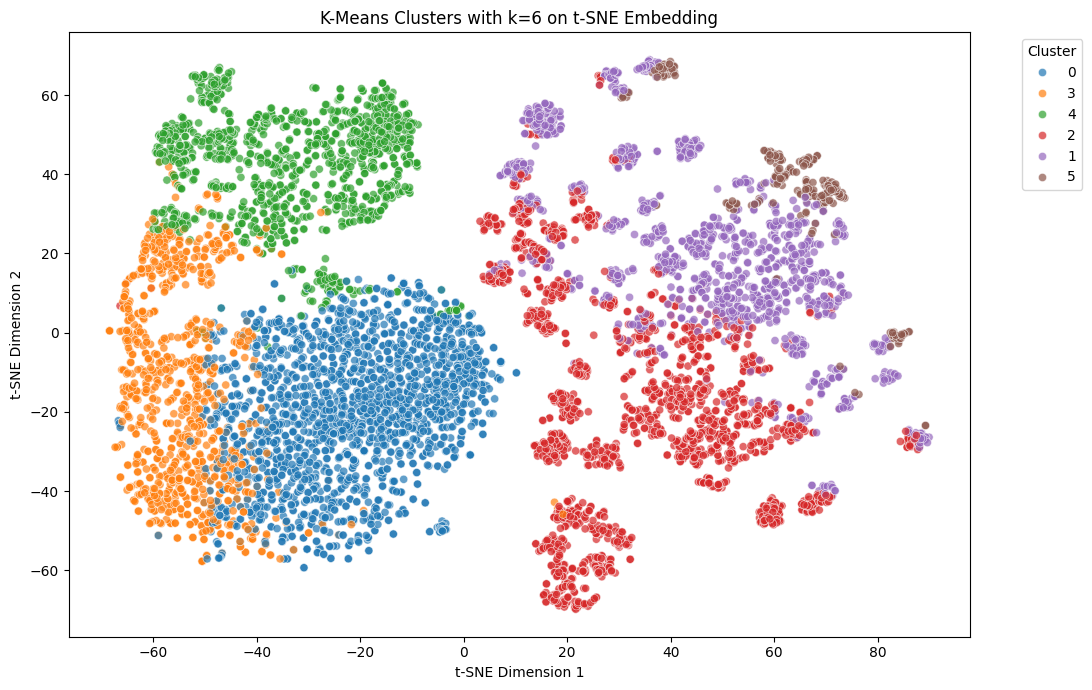

In [65]:
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=tsne_clusters_df,
    x="t-SNE 1",
    y="t-SNE 2",
    hue="Cluster",
    alpha=0.7,
    s=35
)

plt.title("K-Means Clusters with k=6 on t-SNE Embedding")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [66]:
ari_score = adjusted_rand_score(y_train, kmeans_6_labels)
print(f"Adjusted Rand Index for K-Means with k=6: {ari_score:.4f}")

Adjusted Rand Index for K-Means with k=6: 0.4203


The Adjusted Rand Index for K-Means with `k = 6` is **0.4203**. This indicates a **moderate match** between the K-Means clusters and the true activity labels. Therefore, unsupervised clustering captures some meaningful structure in the data, but it does **not fully recover the six activity groups**.

In [67]:
y_train

0               STANDING
1               STANDING
2               STANDING
3               STANDING
4               STANDING
              ...       
7347    WALKING_UPSTAIRS
7348    WALKING_UPSTAIRS
7349    WALKING_UPSTAIRS
7350    WALKING_UPSTAIRS
7351    WALKING_UPSTAIRS
Name: Activity, Length: 7352, dtype: object

In [68]:
dynamic_activities = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS"
]
y_train_binary = train_df["Activity"].isin(dynamic_activities).astype(int).to_numpy()
y_test_binary = test_df["Activity"].isin(dynamic_activities).astype(int).to_numpy()

In [69]:
X_train_sgd = X_train_scaled.to_numpy()
X_test_sgd = X_test_scaled.to_numpy()

In [70]:
print("Training feature shape:", X_train_sgd.shape)
print("Test feature shape:", X_test_sgd.shape)

Training feature shape: (7352, 561)
Test feature shape: (2947, 561)


In [1]:
import sys
sys.path.append("..")
from src.mini_batch_sgd_logistic_regression import MiniBatchSGDLogisticRegression

In [184]:
learning_rate = 0.01
n_epochs = 100

In [185]:

batch_sizes = {
    "Batch size = 32": 32,
    "Batch size = 128": 128,
    "Full batch": X_train_sgd.shape[0]
}

scratch_models = {}
mlflow_results = []

for label, batch_size in batch_sizes.items():
    with mlflow.start_run(run_name=label) as run:
        model = MiniBatchSGDLogisticRegression(
            learning_rate=learning_rate,
            n_epochs=n_epochs,
            batch_size=batch_size,
            random_state=RANDOM_SEED
        )

        mlflow.log_params({
            "learning_rate": learning_rate,
            "n_epochs": n_epochs,
            "batch_size": batch_size
        })

        mlflow.set_tags({
            "model_type": "from_scratch_mini_batch_sgd_logistic_regression",
            "task": "binary_dynamic_vs_static",
            "batch_setup": label,
            "model_saved": "true"
        })

        model.fit(
            X_train_sgd,
            y_train_binary,
        )

        y_pred = model.predict(X_test_sgd)

        test_accuracy = accuracy_score(y_test_binary, y_pred)
        test_macro_f1 = f1_score(
            y_test_binary,
            y_pred,
            average="macro"
        )

        mlflow.log_metrics({
            "test_accuracy": test_accuracy,
            "test_macro_f1": test_macro_f1,
            "final_train_loss": model.loss_history[-1]
        })

        # Save the custom model as a pickle artifact
        with tempfile.TemporaryDirectory() as temp_dir:
            model_path = Path(temp_dir) / "mini_batch_sgd_logistic_regression.pkl"

            with open(model_path, "wb") as file:
                pickle.dump(model, file)

            mlflow.log_artifact(
                str(model_path),
                artifact_path="saved_model"
            )

        scratch_models[label] = model

        mlflow_results.append({
            "Run ID": run.info.run_id,
            "Experiment": label,
            "Batch Size": batch_size,
            "Test Accuracy": test_accuracy,
            "Test Macro F1": test_macro_f1,
            "Final Train Loss": model.loss_history[-1]
        })

🏃 View run Batch size = 32 at: http://127.0.0.1:5000/#/experiments/1/runs/3351b94f8a5c48ee9a9608722a9c4c75
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run Batch size = 128 at: http://127.0.0.1:5000/#/experiments/1/runs/8f7cbe9012e84ddab5a7b4f6d0a60dbc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run Full batch at: http://127.0.0.1:5000/#/experiments/1/runs/5b88e6f1cda049e0958e0bb8c826eb4e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


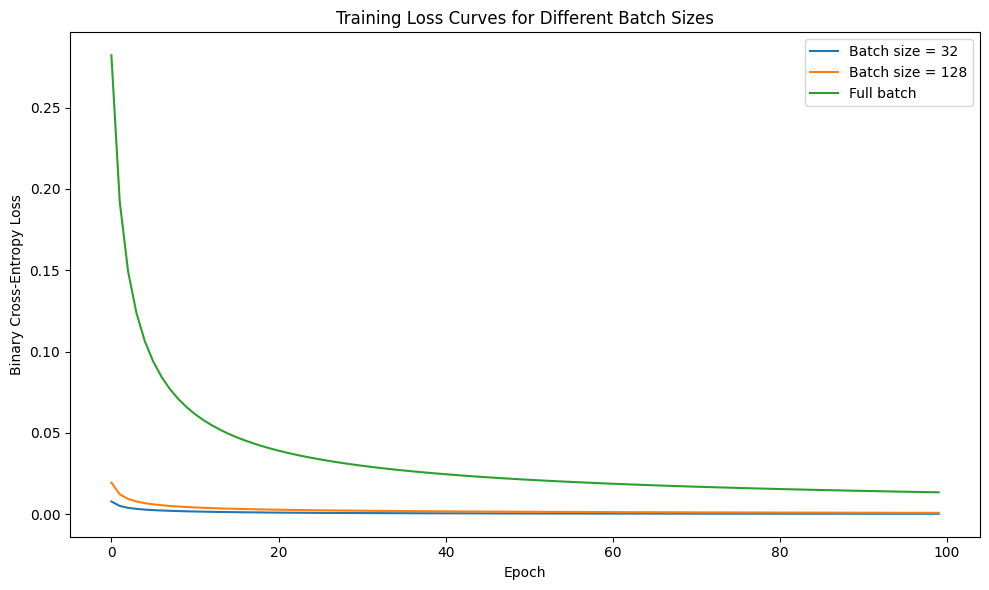

In [186]:
plt.figure(figsize=(10, 6))

for label, model in scratch_models.items():
    plt.plot(model.loss_history, label=label)

plt.title("Training Loss Curves for Different Batch Sizes")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.tight_layout()
plt.show()

### Effect of Batch Size on Convergence

The smaller batch sizes, `32` and `128`, converge much faster than full-batch gradient descent, reaching near-zero loss within only a few epochs. The full-batch model improves more slowly because it performs only one weight update per epoch, while mini-batch models perform many updates during each epoch.

In [189]:
mlflow_results_df = pd.DataFrame(mlflow_results)
mlflow_results_df

,Run ID,Experiment,Batch Size,Test Accuracy,Test Macro F1,Final Train Loss
0,3351b94f8a5c48ee9a9608722a9c4c75,Batch size = 32,32,0.999661,0.99966,0.000236
1,8f7cbe9012e84ddab5a7b4f6d0a60dbc,Batch size = 128,128,0.999661,0.99966,0.000834
2,5b88e6f1cda049e0958e0bb8c826eb4e,Full batch,7352,0.999661,0.99966,0.013438


In [190]:
for label, model in scratch_models.items():
    y_pred = model.predict(X_test_sgd)
    accuracy = accuracy_score(y_test_binary, y_pred)
    print(f"{label}: Test Accuracy = {accuracy:.4f}")

Batch size = 32: Test Accuracy = 0.9997
Batch size = 128: Test Accuracy = 0.9997
Full batch: Test Accuracy = 0.9997


### Comparison with `SGDClassifier` from sklearn

My implementation manually shows the full mini-batch training loop: shuffling, batch-wise gradient calculation, weight updates, and full training loss tracking after each epoch. `sklearn.linear_model.SGDClassifier(loss="log_loss")` exposes parameters that my implementation does not, such as regularization through `penalty` and `alpha`. On the other hand, my implementation makes the mini-batch gradient updates explicit, while sklearn handles the optimization details internally. 

In [77]:
sklearn_sgd = SGDClassifier(
    loss="log_loss",
    learning_rate="constant",
    eta0=learning_rate,
    max_iter=n_epochs,
    tol=None,
    penalty=None,
    random_state=RANDOM_SEED,
    shuffle=True
)

In [78]:
sklearn_sgd_fit_start = time.perf_counter()
sklearn_sgd.fit(X_train_sgd, y_train_binary)
sklearn_sgd_fit_time = time.perf_counter() - sklearn_sgd_fit_start
print(f"sklearn SGDClassifier Fit Time: {sklearn_sgd_fit_time:.4f} seconds")

sklearn SGDClassifier Fit Time: 1.3742 seconds


In [79]:
sklearn_predictions = sklearn_sgd.predict(X_test_sgd)
sklearn_accuracy = accuracy_score(y_test_binary, sklearn_predictions)

print(f"sklearn SGDClassifier Test Accuracy: {sklearn_accuracy:.4f}")

sklearn SGDClassifier Test Accuracy: 1.0000


In [80]:
scratch_accuracy_32 = accuracy_score(
    y_test_binary,
    scratch_models["Batch size = 32"].predict(X_test_sgd)
)

accuracy_difference_pp = abs(scratch_accuracy_32 - sklearn_accuracy) * 100

print(f"From-scratch Mini-Batch SGD Accuracy: {scratch_accuracy_32:.4f}")
print(f"sklearn SGDClassifier Accuracy: {sklearn_accuracy:.4f}")
print(f"Absolute difference: {accuracy_difference_pp:.2f} percentage points")

From-scratch Mini-Batch SGD Accuracy: 0.9997
sklearn SGDClassifier Accuracy: 1.0000
Absolute difference: 0.03 percentage points


### Comparison with `SGDClassifier`

All three from-scratch models achieved a test accuracy of **99.97%**, while `sklearn.linear_model.SGDClassifier(loss="log_loss")` achieved **100.00%** accuracy. The difference is only **0.03 percentage points**, which is far below the allowed 2 pp threshold, so the results agree very closely. This tiny discrepancy is expected because sklearn uses its own internal optimization details and implementation choices.

### Why Mini-Batch SGD Can Generalize Well

Mini-batch SGD can often perform better on new, unseen data because it doesn’t learn in a perfectly smooth way. Instead, each small batch introduces a bit of randomness in the updates, which prevents the model from fitting the training data too tightly. This “noisy” learning process helps the model explore more solutions and often leads to a model that generalizes better.

### What Would Change with a Decaying Learning Rate?

With a decaying learning rate, both loss curves would likely become more stable later in training because the updates would get smaller over time. The `batch_size = 32` model would probably benefit more, since its updates are naturally noisier and the smaller learning rate would reduce late-stage fluctuations. The full-batch model is already smooth, so the decay would mainly slow down its later updates rather than noticeably improve stability.

In [81]:
y_train_multi = train_df["Activity"].copy()
y_test_multi = test_df["Activity"].copy()
activity_labels = [
    "LAYING",
    "SITTING",
    "STANDING",
    "WALKING",
    "WALKING_DOWNSTAIRS",
    "WALKING_UPSTAIRS"
]

In [82]:
y_train_multi.unique()

array(['STANDING', 'SITTING', 'LAYING', 'WALKING', 'WALKING_DOWNSTAIRS',
       'WALKING_UPSTAIRS'], dtype=object)

In [83]:
def evaluate_model(model, X_train_data, X_test_data, y_train, y_test):
    model.fit(X_train_data, y_train)
    
    y_train_pred = model.predict(X_train_data)
    y_test_pred = model.predict(X_test_data)
    
    results = {
        "model": model,
        "train_accuracy": accuracy_score(y_train, y_train_pred),
        "test_accuracy": accuracy_score(y_test, y_test_pred),
        "macro_f1": f1_score(y_test, y_test_pred, average="macro"),
        "y_test_pred": y_test_pred
    }
    
    return results

In [84]:
def plot_normalized_confusion_matrix(y_true, y_pred, labels, title):
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels,
        normalize="true"
    )
    
    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        xticklabels=labels,
        yticklabels=labels
    )
    plt.title(title)
    plt.xlabel("Predicted Activity")
    plt.ylabel("True Activity")
    plt.tight_layout()
    plt.show()

In [85]:
### find which two classes are most often confused by a classification model.
def get_most_confused_pair(y_true, y_pred, labels):
    # Compute normalized confusion matrix
    # normalize="true" means each row sums to 1 (row-wise probabilities)
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=labels,
        normalize="true"
    )
    
    pair_confusions = []
    
    # Compare every pair of classes (i, j)
    # We use i < j to avoid duplicate pairs (A↔B and B↔A separately)
    for i in range(len(labels)):
        for j in range(i + 1, len(labels)):
            
            # Confusion in both directions:
            # i misclassified as j + j misclassified as i
            combined_confusion = cm[i, j] + cm[j, i]
            
            # Store result as a readable record
            pair_confusions.append({
                "Activity Pair": f"{labels[i]} ↔ {labels[j]}",
                "Combined Normalized Confusion": combined_confusion
            })
    
    # Convert list of dictionaries into a DataFrame for easy sorting
    pair_confusions_df = pd.DataFrame(pair_confusions)
    
    # Sort pairs by highest confusion and return the top one
    return pair_confusions_df.sort_values(
        "Combined Normalized Confusion",
        ascending=False
    ).iloc[0]

### KNN

In [192]:
knn_k_values = [1, 3, 5, 11, 21]

model_selection_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED
)

model_selection_scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro"
}

knn_results = []

for k in knn_k_values:
    knn = Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k))
    ])
    
    cv_results = cross_validate(
        knn,
        X_train,
        y_train_multi,
        cv=model_selection_cv,
        scoring=model_selection_scoring,
    )

    knn_results.append({
        "k": k,
        "cv_accuracy_mean": cv_results["test_accuracy"].mean(),
        "cv_accuracy_std": cv_results["test_accuracy"].std(),
        "cv_macro_f1_mean": cv_results["test_macro_f1"].mean(),
        "cv_macro_f1_std": cv_results["test_macro_f1"].std()
    })

knn_results_df = pd.DataFrame(knn_results)
knn_results_df


,k,cv_accuracy_mean,cv_accuracy_std,cv_macro_f1_mean,cv_macro_f1_std
0,1,0.965859,0.004879,0.967870,0.004882
1,3,0.964498,0.003326,0.966335,0.003263
2,5,0.961098,0.004846,0.963038,0.004719
3,11,0.955250,0.003297,0.957017,0.003245
4,21,0.948449,0.004032,0.949904,0.004439


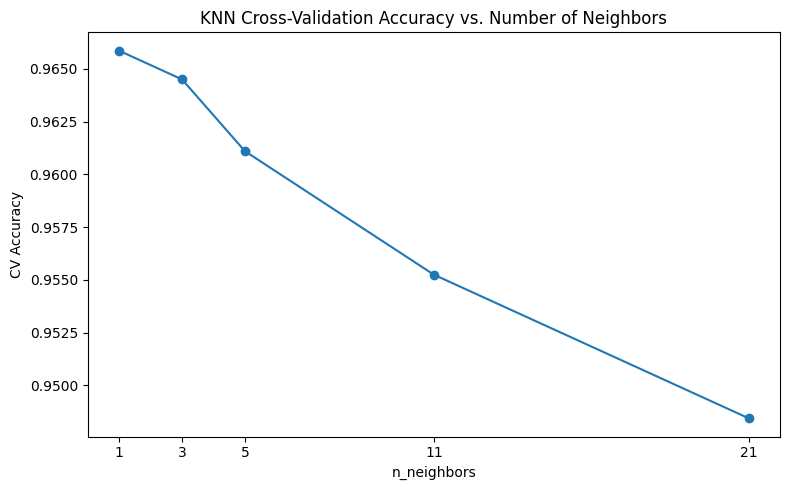

In [193]:
plt.figure(figsize=(8, 5))
plt.plot(
    knn_results_df["k"],
    knn_results_df["cv_accuracy_mean"],
    marker="o"
)
plt.title("KNN Cross-Validation Accuracy vs. Number of Neighbors")
plt.xlabel("n_neighbors")
plt.ylabel("CV Accuracy")
plt.xticks(knn_k_values)
plt.tight_layout()
plt.show()

In [194]:
best_knn_row = knn_results_df.loc[
    knn_results_df["cv_accuracy_mean"].idxmax()
]
best_knn_k = int(best_knn_row["k"])

best_knn_model = KNeighborsClassifier(n_neighbors=best_knn_k)
best_knn_result = evaluate_model(
    best_knn_model,
    X_train_scaled,
    X_test_scaled,
    y_train_multi,
    y_test_multi
)

print(f"Best KNN k from CV: {best_knn_k}")
print(f"CV Accuracy: {best_knn_row['cv_accuracy_mean']:.4f} ± {best_knn_row['cv_accuracy_std']:.4f}")
print(f"Test Accuracy: {best_knn_result['test_accuracy']:.4f}")
print(f"Test Macro F1: {best_knn_result['macro_f1']:.4f}")

Best KNN k from CV: 1
CV Accuracy: 0.9659 ± 0.0049
Test Accuracy: 0.8534
Test Macro F1: 0.8509


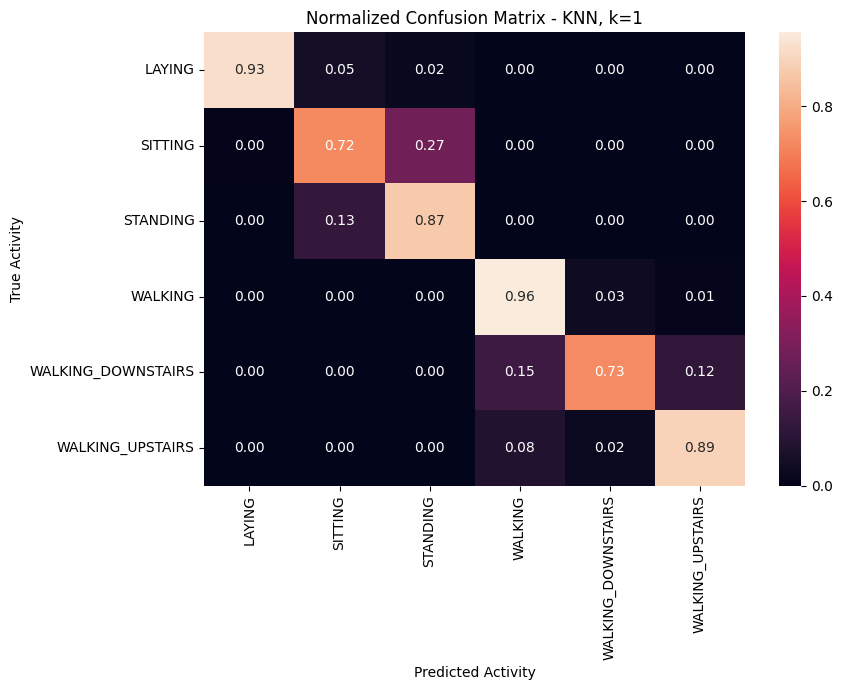

In [195]:
plot_normalized_confusion_matrix(
    y_test_multi,
    best_knn_result["y_test_pred"],
    activity_labels,
    f"Normalized Confusion Matrix - KNN, k={best_knn_k}"
)

In [196]:
best_knn_confused_pair = get_most_confused_pair(
    y_test_multi,
    best_knn_result["y_test_pred"],
    activity_labels
)

best_knn_confused_pair

Activity Pair                    SITTING ↔ STANDING
Combined Normalized Confusion              0.400732
Name: 5, dtype: object

### KNN Results

For KNN, I tested `k ∈ {1, 3, 5, 11, 21}`. The best result from cross-validation was achieved with **k = 1**, with a **CV accuracy of 96.59% ± 0.49%**. On the test set, this model achieved a **test accuracy of 85.34%** and a **macro F1-score of 85.09%**.

From the cross-validation results, the performance slightly decreases as `k` increases. This means that, for this dataset, using only the nearest neighbor worked better than averaging over more neighbors. A possible reason is that the activity patterns are already well separated in the feature space, so adding more neighbors may introduce samples from similar but different activities and make the decision less precise.

From the normalized confusion matrix for **KNN with k = 1**, the model classifies `LAYING`, `WALKING`, and `WALKING_UPSTAIRS` quite well, with correct classification rates of about **93%**, **96%**, and **89%**. `STANDING` is also classified reasonably well with about **87%** correct predictions.

The weaker results appear for `SITTING` and `WALKING_DOWNSTAIRS`. `SITTING` is correctly classified only about **72%** of the time, with many samples confused as `STANDING`. `WALKING_DOWNSTAIRS` is also correctly classified about **73%** of the time, with confusion mainly toward `WALKING` and `WALKING_UPSTAIRS`.

The most confused activity pair is **`SITTING` ↔ `STANDING`**, with a combined normalized confusion of about **0.401**. This makes sense because these two activities are both static activities and can produce very similar smartphone sensor patterns.

### Linear SVM

In [197]:
svm_c_values = [0.01, 0.1, 1, 10]

svm_results = []

for c_value in svm_c_values:
    svm = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearSVC(
            C=c_value,
            max_iter=20000,
            random_state=RANDOM_SEED
        ))
    ])
    
    cv_results = cross_validate(
        svm,
        X_train,
        y_train_multi,
        cv=model_selection_cv,
        scoring=model_selection_scoring,
        n_jobs=-1
    )

    svm_results.append({
        "C": c_value,
        "cv_accuracy_mean": cv_results["test_accuracy"].mean(),
        "cv_accuracy_std": cv_results["test_accuracy"].std(),
        "cv_macro_f1_mean": cv_results["test_macro_f1"].mean(),
        "cv_macro_f1_std": cv_results["test_macro_f1"].std()
    })

svm_results_df = pd.DataFrame(svm_results)
svm_results_df


,C,cv_accuracy_mean,cv_accuracy_std,cv_macro_f1_mean,cv_macro_f1_std
0,0.01,0.983269,0.003913,0.984323,0.003670
1,0.10,0.985038,0.003965,0.986073,0.003668
2,1.00,0.982862,0.003343,0.983965,0.003087
3,10.00,0.978237,0.004036,0.979334,0.003856


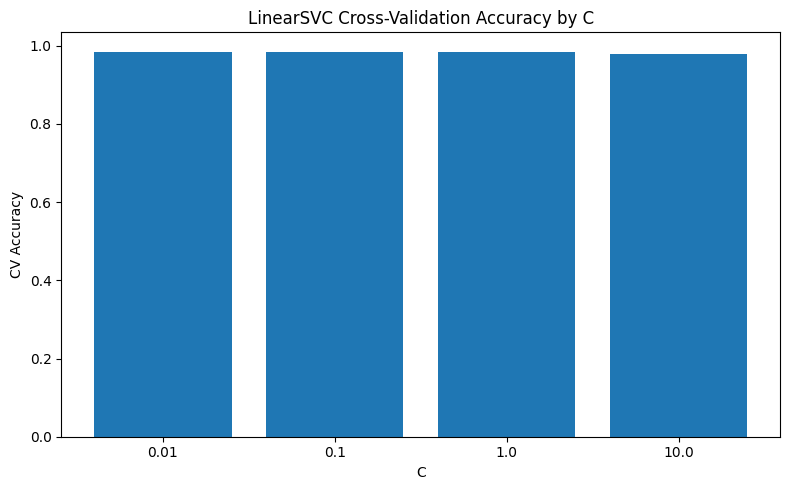

In [198]:
plt.figure(figsize=(8, 5))
plt.bar(
    svm_results_df["C"].astype(str),
    svm_results_df["cv_accuracy_mean"]
)
plt.title("LinearSVC Cross-Validation Accuracy by C")
plt.xlabel("C")
plt.ylabel("CV Accuracy")
plt.tight_layout()
plt.show()

In [199]:
best_svm_row = svm_results_df.loc[
    svm_results_df["cv_accuracy_mean"].idxmax()
]
best_svm_c = best_svm_row["C"]

best_svm_model = LinearSVC(
    C=best_svm_c,
    max_iter=20000,
    random_state=RANDOM_SEED
)
best_svm_result = evaluate_model(
    best_svm_model,
    X_train_scaled,
    X_test_scaled,
    y_train_multi,
    y_test_multi
)

print(f"Best LinearSVC C from CV: {best_svm_c}")
print(f"CV Accuracy: {best_svm_row['cv_accuracy_mean']:.4f} ± {best_svm_row['cv_accuracy_std']:.4f}")
print(f"Test Accuracy: {best_svm_result['test_accuracy']:.4f}")
print(f"Test Macro F1: {best_svm_result['macro_f1']:.4f}")

Best LinearSVC C from CV: 0.1
CV Accuracy: 0.9850 ± 0.0040
Test Accuracy: 0.9620
Test Macro F1: 0.9629


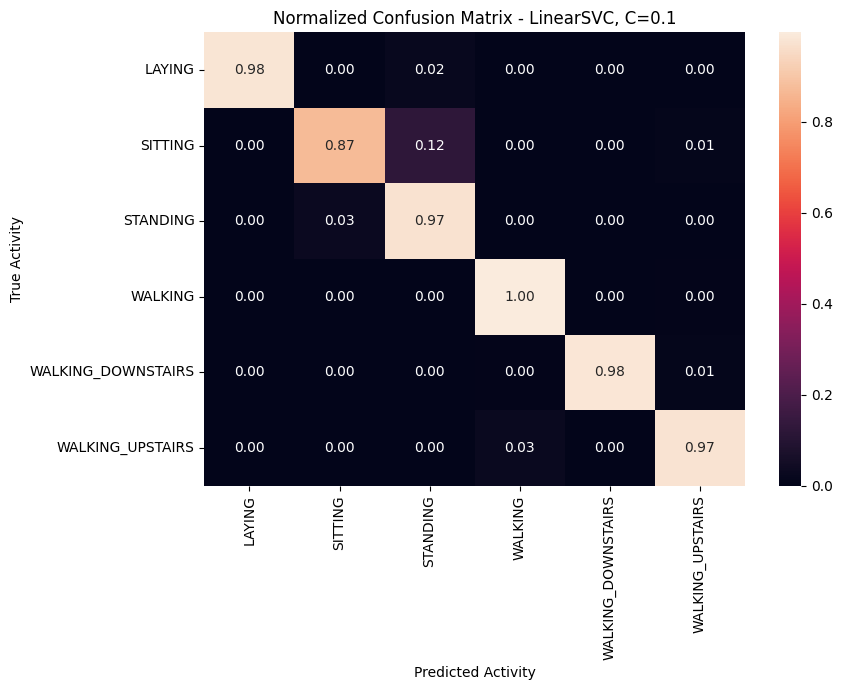

In [200]:
plot_normalized_confusion_matrix(
    y_test_multi,
    best_svm_result["y_test_pred"],
    activity_labels,
    f"Normalized Confusion Matrix - LinearSVC, C={best_svm_c}"
)

In [201]:
best_svm_confused_pair = get_most_confused_pair(
    y_test_multi,
    best_svm_result["y_test_pred"],
    activity_labels
)

best_svm_confused_pair

Activity Pair                    SITTING ↔ STANDING
Combined Normalized Confusion              0.152432
Name: 5, dtype: object

### LinearSVC Results

For LinearSVC, I tested `C ∈ {0.01, 0.1, 1, 10}`. The best performance was achieved with **C = 0.1**, reaching a **test accuracy of 96.20%** and a **macro F1-score of 96.29%**. The results are very similar across all tested values, but `C = 0.1` gives the best overall score.

From the normalized confusion matrix, the model classifies most activities very well. `WALKING` is predicted almost perfectly, while `LAYING`, `STANDING`, `WALKING_DOWNSTAIRS`, and `WALKING_UPSTAIRS` also have very high correct classification rates. The weakest class is `SITTING`, where about **12%** of samples are predicted as `STANDING`.

The most confused activity pair is again **`SITTING` ↔ `STANDING`**, with a combined normalized confusion of **0.152**. This is the same difficult pair seen with KNN, but LinearSVC handles it noticeably better.

### Decision Tree

In [96]:
tree_depth_values = [3, 5, 10, None]

tree_results = []

for depth in tree_depth_values:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_SEED
    )

    cv_results = cross_validate(
        tree,
        X_train,
        y_train_multi,
        cv=model_selection_cv,
        scoring=model_selection_scoring,
        return_train_score=True,
        n_jobs=-1
    )

    tree_results.append({
        "max_depth": str(depth),
        "train_accuracy_mean": cv_results["train_accuracy"].mean(),
        "cv_accuracy_mean": cv_results["test_accuracy"].mean(),
        "cv_accuracy_std": cv_results["test_accuracy"].std(),
        "cv_macro_f1_mean": cv_results["test_macro_f1"].mean(),
        "cv_macro_f1_std": cv_results["test_macro_f1"].std()
    })

tree_results_df = pd.DataFrame(tree_results)
tree_results_df

,max_depth,train_accuracy_mean,cv_accuracy_mean,cv_accuracy_std,cv_macro_f1_mean,cv_macro_f1_std
0,3,0.788119,0.786452,0.003116,0.715935,0.003189
1,5,0.919580,0.901659,0.005174,0.897082,0.005316
2,10,0.989357,0.937024,0.004140,0.935213,0.003694
3,None,1.000000,0.932806,0.003777,0.931003,0.003910


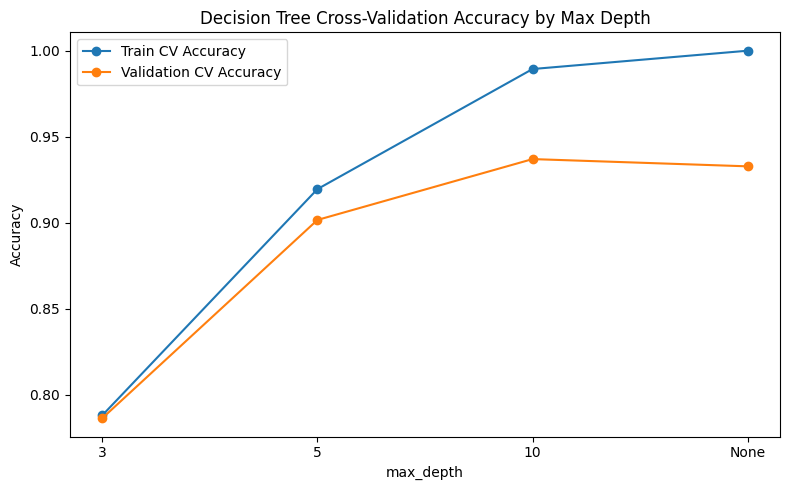

In [97]:
plt.figure(figsize=(8, 5))

plt.plot(
    tree_results_df["max_depth"],
    tree_results_df["train_accuracy_mean"],
    marker="o",
    label="Train CV Accuracy"
)

plt.plot(
    tree_results_df["max_depth"],
    tree_results_df["cv_accuracy_mean"],
    marker="o",
    label="Validation CV Accuracy"
)

plt.title("Decision Tree Cross-Validation Accuracy by Max Depth")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

In [98]:
best_tree_row = tree_results_df.loc[
    tree_results_df["cv_accuracy_mean"].idxmax()
]
best_tree_depth = best_tree_row["max_depth"]
best_tree_depth_value = (
    None if str(best_tree_depth) == "None"
    else int(best_tree_depth)
)

best_tree_model = DecisionTreeClassifier(
    max_depth=best_tree_depth_value,
    random_state=RANDOM_SEED
)
best_tree_result = evaluate_model(
    best_tree_model,
    X_train,
    X_test,
    y_train_multi,
    y_test_multi
)

print(f"Best Decision Tree max_depth from CV: {best_tree_depth}")
print(f"CV Accuracy: {best_tree_row['cv_accuracy_mean']:.4f} ± {best_tree_row['cv_accuracy_std']:.4f}")
print(f"Test Accuracy: {best_tree_result['test_accuracy']:.4f}")
print(f"Test Macro F1: {best_tree_result['macro_f1']:.4f}")

Best Decision Tree max_depth from CV: 10
CV Accuracy: 0.9370 ± 0.0041
Test Accuracy: 0.8626
Test Macro F1: 0.8590


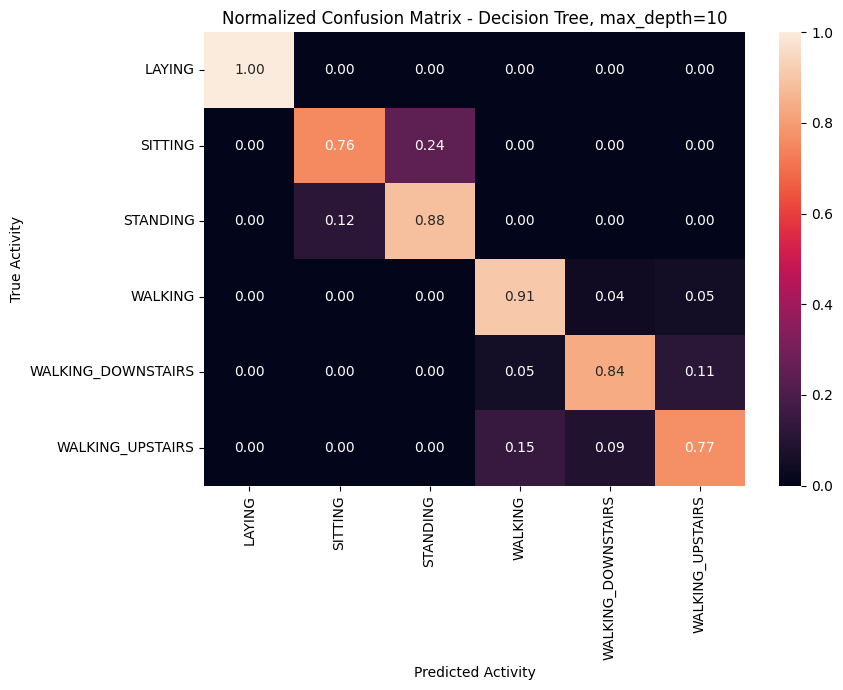

In [99]:
plot_normalized_confusion_matrix(
    y_test_multi,
    best_tree_result["y_test_pred"],
    activity_labels,
    f"Normalized Confusion Matrix - Decision Tree, max_depth={best_tree_depth}"
)

In [100]:
best_tree_confused_pair = get_most_confused_pair(
    y_test_multi,
    best_tree_result["y_test_pred"],
    activity_labels
)

best_tree_confused_pair

Activity Pair                    SITTING ↔ STANDING
Combined Normalized Confusion              0.358904
Name: 5, dtype: object

### Decision Tree Results

For the Decision Tree, I tested `max_depth ∈ {3, 5, 10, None}`. The best cross-validation result was achieved with **max_depth = 10**, giving a **CV accuracy of 93.70% ± 0.41%** and a **macro F1-score of 93.52% ± 0.37%**. As depth increases, training accuracy keeps improving and reaches **100%** with no depth limit, while validation accuracy slightly drops after depth 10. This indicates that the tree starts to overfit when it becomes too deep.

From the normalized confusion matrix for **Decision Tree with max_depth = 10**, `LAYING` is classified perfectly, with a correct classification rate of **100%**. `WALKING`, `STANDING`, and `WALKING_DOWNSTAIRS` are also recognized fairly well, with correct classification rates of about **91%**, **88%**, and **84%**.

The weaker results appear for `SITTING` and `WALKING_UPSTAIRS`. `SITTING` is correctly classified about **76%** of the time, with most of the mistakes going to `STANDING`. `WALKING_UPSTAIRS` is correctly classified about **77%** of the time, with confusion mainly toward `WALKING` and `WALKING_DOWNSTAIRS`.

The most confused activity pair is again **`SITTING` ↔ `STANDING`**, with a combined normalized confusion of **0.359**. This is the same most-confused pair found for the other models as well, showing that these two static activities are consistently the hardest to separate.

In [101]:
best_model_summary = pd.DataFrame([
    {
        "Model": f"KNN (k={best_knn_k})",
        "Test Accuracy": best_knn_result["test_accuracy"],
        "Macro F1": best_knn_result["macro_f1"],
        "Most Confused Pair": best_knn_confused_pair["Activity Pair"]
    },
    {
        "Model": f"LinearSVC (C={best_svm_c})",
        "Test Accuracy": best_svm_result["test_accuracy"],
        "Macro F1": best_svm_result["macro_f1"],
        "Most Confused Pair": best_svm_confused_pair["Activity Pair"]
    },
    {
        "Model": f"Decision Tree (max_depth={best_tree_depth})",
        "Test Accuracy": best_tree_result["test_accuracy"],
        "Macro F1": best_tree_result["macro_f1"],
        "Most Confused Pair": best_tree_confused_pair["Activity Pair"]
    }
])

best_model_summary

,Model,Test Accuracy,Macro F1,Most Confused Pair
0,KNN (k=1),0.853410,0.850884,SITTING ↔ STANDING
1,LinearSVC (C=0.1),0.961995,0.962914,SITTING ↔ STANDING
2,Decision Tree (max_depth=10),0.862572,0.859044,SITTING ↔ STANDING


### Overall Baseline Classifier Comparison

Among the three baseline classifiers, **LinearSVC performed best**, achieving **96.20% test accuracy** and **96.29% macro F1-score**. KNN achieved a lower result with **85.34% test accuracy** and **85.09% macro F1-score**, while the Decision Tree performed slightly better than KNN with **86.26% test accuracy** and **85.90% macro F1-score**.

Across all three models, the most confused activity pair was consistently **`SITTING` ↔ `STANDING`**. This confirms that these two static activities are the hardest to distinguish, likely because they produce very similar sensor patterns.

Overall, LinearSVC is clearly the strongest baseline model for this dataset among the three tested methods. It achieved the highest accuracy and macro F1-score, while KNN and Decision Tree had weaker performance and more confusion between similar activities.

### 5.1 Random Forest

In [102]:
rf_n_estimators_values = [50, 100, 300]
rf_max_features_values = ["sqrt", "log2"]

In [103]:
stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED
)

In [104]:
rf_cv_results = []
for n_estimators in rf_n_estimators_values:
    for max_features in rf_max_features_values:
        rf = RandomForestClassifier(
            n_estimators=n_estimators,
            max_features=max_features,
            random_state=RANDOM_SEED,
        )
        
        cv_scores = cross_val_score(
            rf,
            X_train,
            y_train_multi,
            cv=stratified_cv,
            scoring="f1_macro",
            n_jobs=-1
        )
        
        rf_cv_results.append({
            "n_estimators": n_estimators,
            "max_features": max_features,
            "cv_macro_f1_mean": cv_scores.mean(),
            "cv_macro_f1_std": cv_scores.std()
        })

rf_cv_results_df = pd.DataFrame(rf_cv_results)
rf_cv_results_df.sort_values(
    by="cv_macro_f1_mean",
    ascending=False
)

,n_estimators,max_features,cv_macro_f1_mean,cv_macro_f1_std
4,300,sqrt,0.982529,0.002692
5,300,log2,0.982185,0.001511
2,100,sqrt,0.982157,0.002018
3,100,log2,0.981139,0.002301
1,50,log2,0.979711,0.002803
0,50,sqrt,0.978893,0.003202


In [105]:
best_rf_row = rf_cv_results_df.loc[
    rf_cv_results_df["cv_macro_f1_mean"].idxmax()
]
best_rf_n_estimators = int(best_rf_row["n_estimators"])
best_rf_max_features = best_rf_row["max_features"]

print(f"Best n_estimators: {best_rf_n_estimators}")
print(f"Best max_features: {best_rf_max_features}")
print(
    f"Best CV Macro F1: "
    f"{best_rf_row['cv_macro_f1_mean']:.4f} ± "
    f"{best_rf_row['cv_macro_f1_std']:.4f}"
)

Best n_estimators: 300
Best max_features: sqrt
Best CV Macro F1: 0.9825 ± 0.0027


In [106]:
best_rf_model = RandomForestClassifier(
    n_estimators=best_rf_n_estimators,
    max_features=best_rf_max_features,
    random_state=RANDOM_SEED,
)

rf_fit_start = time.perf_counter()
best_rf_model.fit(X_train, y_train_multi)
rf_fit_time = time.perf_counter() - rf_fit_start

print(f"Random Forest Fit Time: {rf_fit_time:.4f} seconds")

Random Forest Fit Time: 38.7862 seconds


In [107]:
rf_test_pred = best_rf_model.predict(X_test)

rf_test_accuracy = accuracy_score(y_test_multi, rf_test_pred)
rf_test_macro_f1 = f1_score(y_test_multi, rf_test_pred, average="macro")

print(f"Random Forest Test Accuracy: {rf_test_accuracy:.4f}")
print(f"Random Forest Test Macro F1: {rf_test_macro_f1:.4f}")

Random Forest Test Accuracy: 0.9287
Random Forest Test Macro F1: 0.9271


In [108]:
rf_feature_importances = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

top_20_rf_features = rf_feature_importances.head(20)

top_20_rf_features

,Feature,Importance
40,tGravityAcc-mean()-X,0.034633
52,tGravityAcc-min()-X,0.030679
558,"angle(X,gravityMean)",0.029352
41,tGravityAcc-mean()-Y,0.029236
56,tGravityAcc-energy()-X,0.025576
53,tGravityAcc-min()-Y,0.024226
50,tGravityAcc-max()-Y,0.024117
559,"angle(Y,gravityMean)",0.022903
49,tGravityAcc-max()-X,0.020365
57,tGravityAcc-energy()-Y,0.016021


<Figure size 1000x800 with 0 Axes>

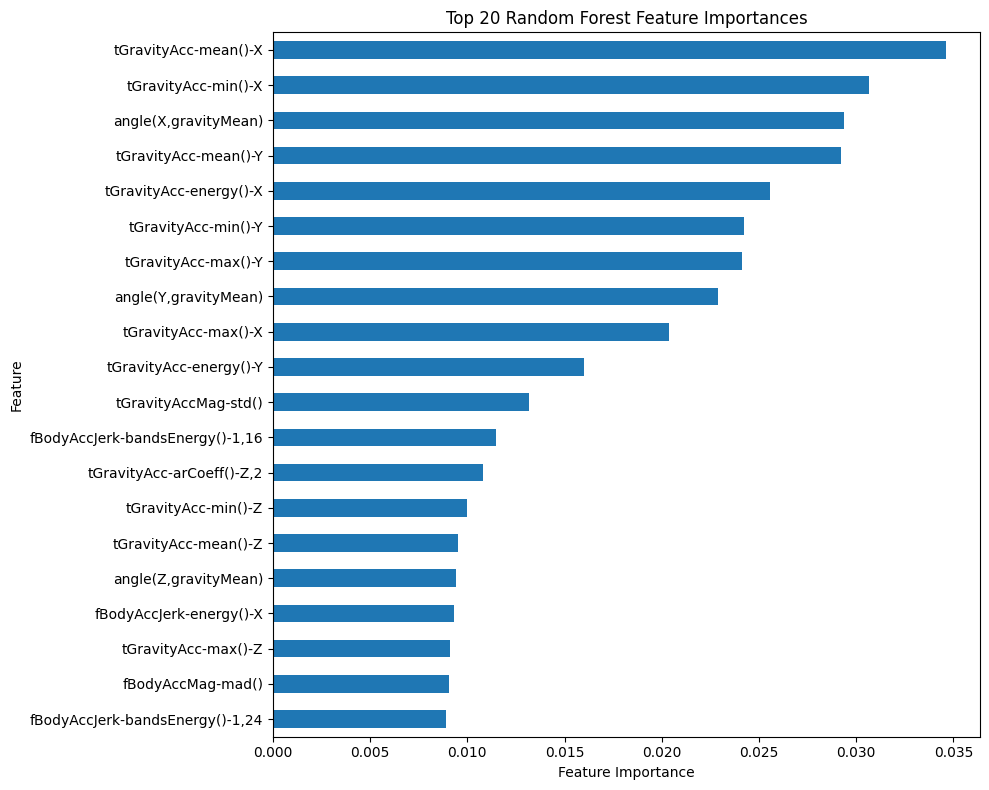

In [109]:
plt.figure(figsize=(10, 8))

top_20_rf_features.sort_values(
    by="Importance",
    ascending=True
).plot(
    kind="barh",
    x="Feature",
    y="Importance",
    legend=False,
    figsize=(10, 8)
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Random Forest Feature Importance

The most important Random Forest features are mainly related to **gravity acceleration** and **body orientation**, such as `tGravityAcc-mean()-X`, `tGravityAcc-min()-X`, and the angle features with `gravityMean`. This partly matches my intuition from Task 1.3, where the gravity-based feature `tGravityAcc-mean()-Z` was useful for separating posture-related activities, especially `LAYING`.

However, the top Random Forest features are not mainly the exact motion features I inspected earlier, such as `fBodyGyro-energy()-Y` or `tBodyGyroJerkMag-mean()`. This suggests that when all six activities are predicted together, the model relies strongly on **orientation and posture information**, while some frequency- and jerk-based motion features still contribute but are less dominant in the top 20.

In [110]:
# Compare absolute correlation ranking vs. Random Forest importance ranking
correlation_ranking_df = pd.DataFrame({
    "Feature": feature_correlations.index,
    "Absolute Correlation": feature_correlations.abs().values
})

correlation_ranking_df["Correlation Rank"] = (
    correlation_ranking_df["Absolute Correlation"]
    .rank(ascending=False, method="min")
    .astype(int)
)

rf_ranking_df = rf_feature_importances.copy()
rf_ranking_df["RF Importance Rank"] = (
    rf_ranking_df["Importance"]
    .rank(ascending=False, method="min")
    .astype(int)
)

ranking_comparison_df = correlation_ranking_df.merge(
    rf_ranking_df,
    on="Feature",
    how="inner"
)

ranking_comparison_df.head()

,Feature,Absolute Correlation,Correlation Rank,Importance,RF Importance Rank
0,tBodyAcc-mean()-X,0.008514,551,0.000218,431
1,tBodyAcc-mean()-Y,0.056229,525,0.000242,400
2,tBodyAcc-mean()-Z,0.041336,533,0.000185,474
3,tBodyAcc-std()-X,0.918398,48,0.003378,77
4,tBodyAcc-std()-Y,0.942390,17,0.000356,315


In [111]:
# Top 20 features by absolute Pearson correlation
top_20_corr_features = ranking_comparison_df.sort_values(
    by="Absolute Correlation",
    ascending=False
)
top_20_corr_features.head(20)

,Feature,Absolute Correlation,Correlation Rank,Importance,RF Importance Rank
366,fBodyAccJerk-entropy()-X,0.977311,1,0.004757,56
367,fBodyAccJerk-entropy()-Y,0.971997,2,0.000825,195
234,tBodyAccJerkMag-entropy(),0.968348,3,0.003709,70
102,tBodyAccJerk-entropy()-X,0.967290,4,0.003345,80
287,fBodyAcc-entropy()-X,0.966413,5,0.004586,58
523,fBodyBodyAccJerkMag-entropy(),0.964093,6,0.000118,551
104,tBodyAccJerk-entropy()-Z,0.961269,7,0.000606,217
103,tBodyAccJerk-entropy()-Y,0.961064,8,0.003525,75
368,fBodyAccJerk-entropy()-Z,0.956419,9,0.000331,330
288,fBodyAcc-entropy()-Y,0.952735,10,0.000265,375


In [112]:
# Top 20 features by Random Forest importance
top_20_rf_features_comparison = ranking_comparison_df.sort_values(
    by="Importance",
    ascending=False
)
top_20_rf_features_comparison.head(20)

,Feature,Absolute Correlation,Correlation Rank,Importance,RF Importance Rank
40,tGravityAcc-mean()-X,0.428896,403,0.034633,1
52,tGravityAcc-min()-X,0.421382,407,0.030679,2
558,"angle(X,gravityMean)",0.410020,411,0.029352,3
41,tGravityAcc-mean()-Y,0.553757,331,0.029236,4
56,tGravityAcc-energy()-X,0.424117,406,0.025576,5
53,tGravityAcc-min()-Y,0.555582,329,0.024226,6
50,tGravityAcc-max()-Y,0.548045,340,0.024117,7
559,"angle(Y,gravityMean)",0.530935,350,0.022903,8
49,tGravityAcc-max()-X,0.435979,400,0.020365,9
57,tGravityAcc-energy()-Y,0.352554,430,0.016021,10


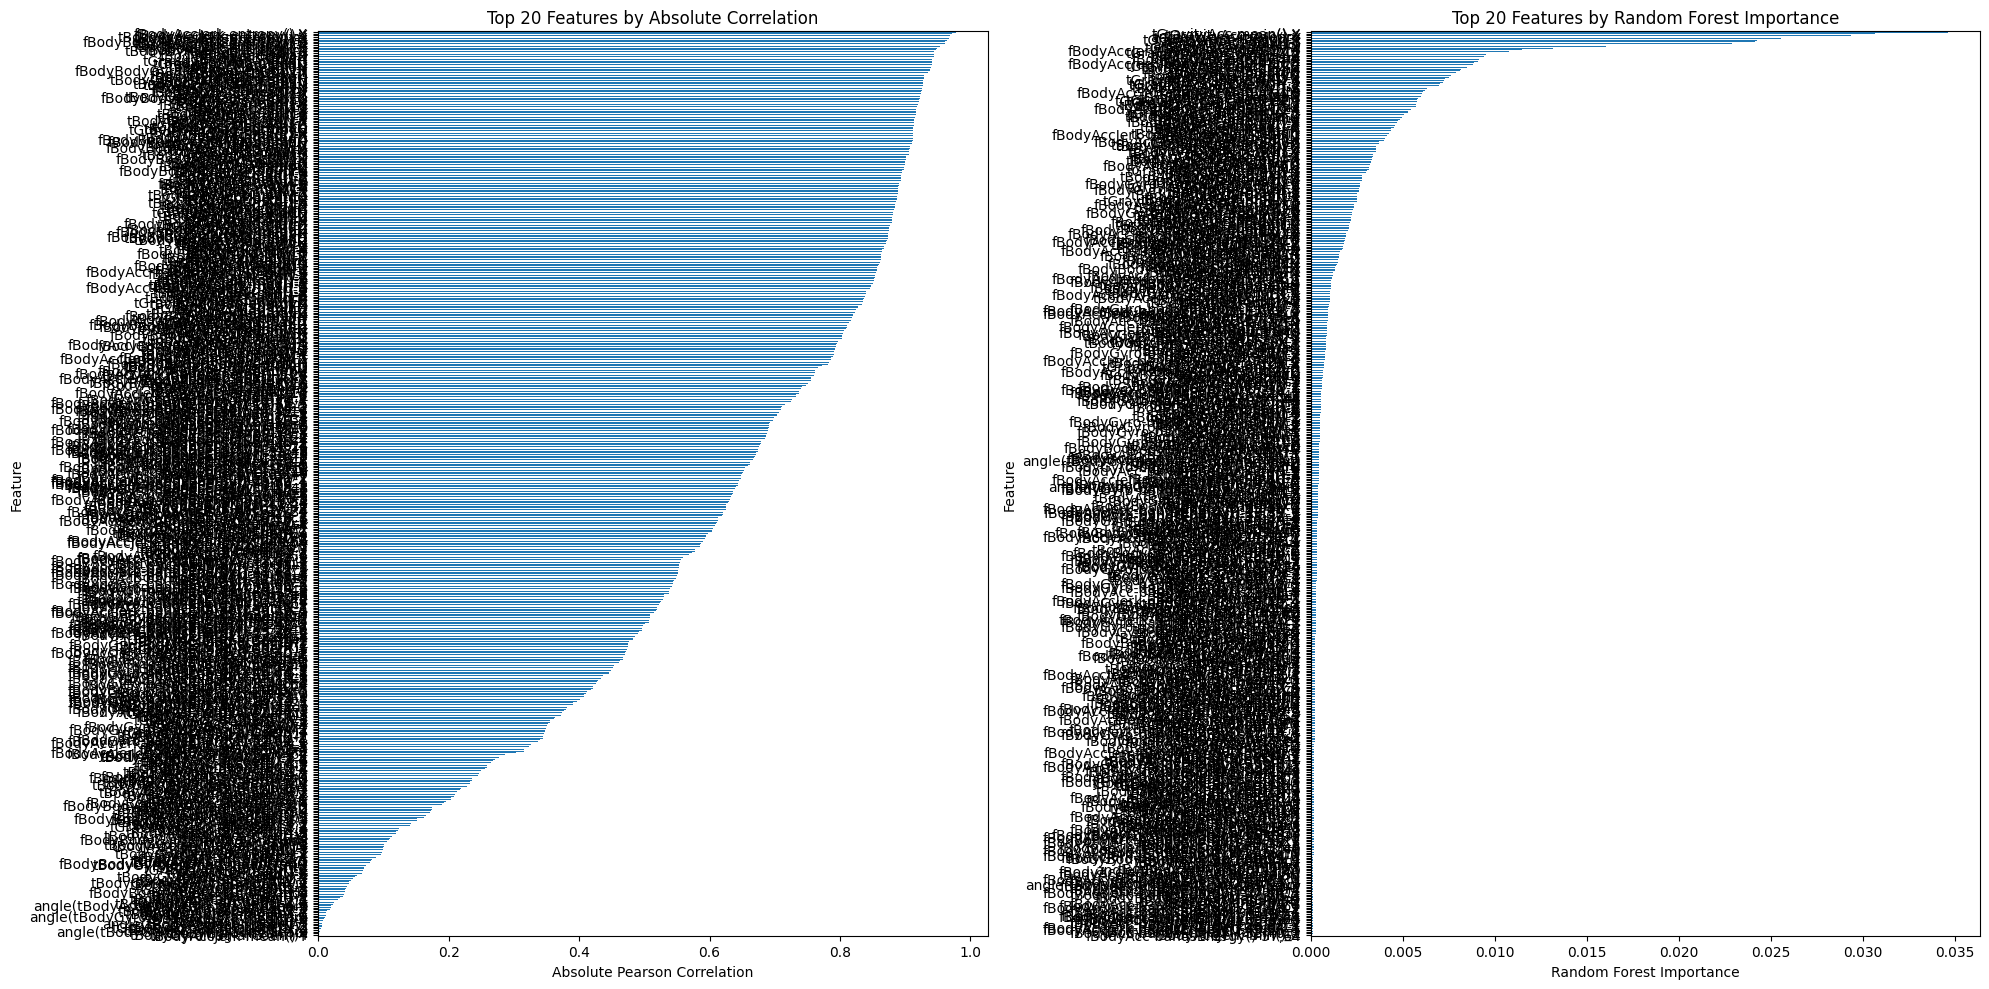

In [113]:
# Side-by-side plot: Correlation ranking vs. Random Forest importance ranking

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

top_20_corr_features.sort_values(
    by="Absolute Correlation",
    ascending=True
).plot(
    kind="barh",
    x="Feature",
    y="Absolute Correlation",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Top 20 Features by Absolute Correlation")
axes[0].set_xlabel("Absolute Pearson Correlation")
axes[0].set_ylabel("Feature")

top_20_rf_features_comparison.sort_values(
    by="Importance",
    ascending=True
).plot(
    kind="barh",
    x="Feature",
    y="Importance",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Top 20 Features by Random Forest Importance")
axes[1].set_xlabel("Random Forest Importance")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()

In [114]:
# How much overlap exists between the two top-20 lists

top_corr_feature_set = set(top_20_corr_features["Feature"])
top_rf_feature_set = set(top_20_rf_features_comparison["Feature"])

common_top_features = top_corr_feature_set.intersection(top_rf_feature_set)

print(f"Number of features appearing in both top-20 lists: {len(common_top_features)}")
print("Shared features:")
for feature in sorted(common_top_features):
    print(feature)

Number of features appearing in both top-20 lists: 561
Shared features:
angle(X,gravityMean)
angle(Y,gravityMean)
angle(Z,gravityMean)
angle(tBodyAccJerkMean),gravityMean)
angle(tBodyAccMean,gravity)
angle(tBodyGyroJerkMean,gravityMean)
angle(tBodyGyroMean,gravityMean)
fBodyAcc-bandsEnergy()-1,16
fBodyAcc-bandsEnergy()-1,16_1
fBodyAcc-bandsEnergy()-1,16_2
fBodyAcc-bandsEnergy()-1,24
fBodyAcc-bandsEnergy()-1,24_1
fBodyAcc-bandsEnergy()-1,24_2
fBodyAcc-bandsEnergy()-1,8
fBodyAcc-bandsEnergy()-1,8_1
fBodyAcc-bandsEnergy()-1,8_2
fBodyAcc-bandsEnergy()-17,24
fBodyAcc-bandsEnergy()-17,24_1
fBodyAcc-bandsEnergy()-17,24_2
fBodyAcc-bandsEnergy()-17,32
fBodyAcc-bandsEnergy()-17,32_1
fBodyAcc-bandsEnergy()-17,32_2
fBodyAcc-bandsEnergy()-25,32
fBodyAcc-bandsEnergy()-25,32_1
fBodyAcc-bandsEnergy()-25,32_2
fBodyAcc-bandsEnergy()-25,48
fBodyAcc-bandsEnergy()-25,48_1
fBodyAcc-bandsEnergy()-25,48_2
fBodyAcc-bandsEnergy()-33,40
fBodyAcc-bandsEnergy()-33,40_1
fBodyAcc-bandsEnergy()-33,40_2
fBodyAcc-bands

In [115]:
# Features ranked very highly by correlation but much lower by RF importance

high_corr_low_rf = ranking_comparison_df.sort_values(
    by=["Correlation Rank", "RF Importance Rank"],
    ascending=[True, False]
).head(10)

high_corr_low_rf[
    ["Feature", "Absolute Correlation", "Correlation Rank", "Importance", "RF Importance Rank"]
]

,Feature,Absolute Correlation,Correlation Rank,Importance,RF Importance Rank
366,fBodyAccJerk-entropy()-X,0.977311,1,0.004757,56
367,fBodyAccJerk-entropy()-Y,0.971997,2,0.000825,195
234,tBodyAccJerkMag-entropy(),0.968348,3,0.003709,70
102,tBodyAccJerk-entropy()-X,0.967290,4,0.003345,80
287,fBodyAcc-entropy()-X,0.966413,5,0.004586,58
523,fBodyBodyAccJerkMag-entropy(),0.964093,6,0.000118,551
104,tBodyAccJerk-entropy()-Z,0.961269,7,0.000606,217
103,tBodyAccJerk-entropy()-Y,0.961064,8,0.003525,75
368,fBodyAccJerk-entropy()-Z,0.956419,9,0.000331,330
288,fBodyAcc-entropy()-Y,0.952735,10,0.000265,375


In [116]:
# Features ranked very highly by RF importance but much lower by correlation

high_rf_low_corr = ranking_comparison_df.sort_values(
    by=["RF Importance Rank", "Correlation Rank"],
    ascending=[True, False]
).head(10)

high_rf_low_corr[
    ["Feature", "Importance", "RF Importance Rank", "Absolute Correlation", "Correlation Rank"]
]

,Feature,Importance,RF Importance Rank,Absolute Correlation,Correlation Rank
40,tGravityAcc-mean()-X,0.034633,1,0.428896,403
52,tGravityAcc-min()-X,0.030679,2,0.421382,407
558,"angle(X,gravityMean)",0.029352,3,0.410020,411
41,tGravityAcc-mean()-Y,0.029236,4,0.553757,331
56,tGravityAcc-energy()-X,0.025576,5,0.424117,406
53,tGravityAcc-min()-Y,0.024226,6,0.555582,329
50,tGravityAcc-max()-Y,0.024117,7,0.548045,340
559,"angle(Y,gravityMean)",0.022903,8,0.530935,350
49,tGravityAcc-max()-X,0.020365,9,0.435979,400
57,tGravityAcc-energy()-Y,0.016021,10,0.352554,430


### Correlation Ranking vs. Random Forest Importance

The top features from the correlation analysis and the top Random Forest features are completely different. This happens because the correlation analysis only checks what separates **DYNAMIC** from **STATIC** activities, while Random Forest tries to separate all **6 activities**. For example, `fBodyAccJerk-entropy()-X` is the most correlated feature with the binary label, but it is not among the most important Random Forest features. It is very useful for telling whether a person is moving or not, but less useful for deciding exactly which activity they are doing.
On the other hand, `tGravityAcc-mean()-X` is the most important Random Forest feature, even though it has much lower correlation with the binary label. This suggests that posture and body orientation are very helpful when distinguishing between specific activities like `SITTING`, `STANDING`, and `LAYING`.


In [117]:
# Top 20 features by Random Forest importance
top_20_rf_feature_names = top_20_rf_features["Feature"].tolist()
# Correlation matrix for those features
top_20_rf_corr_matrix = X_train[top_20_rf_feature_names].corr()

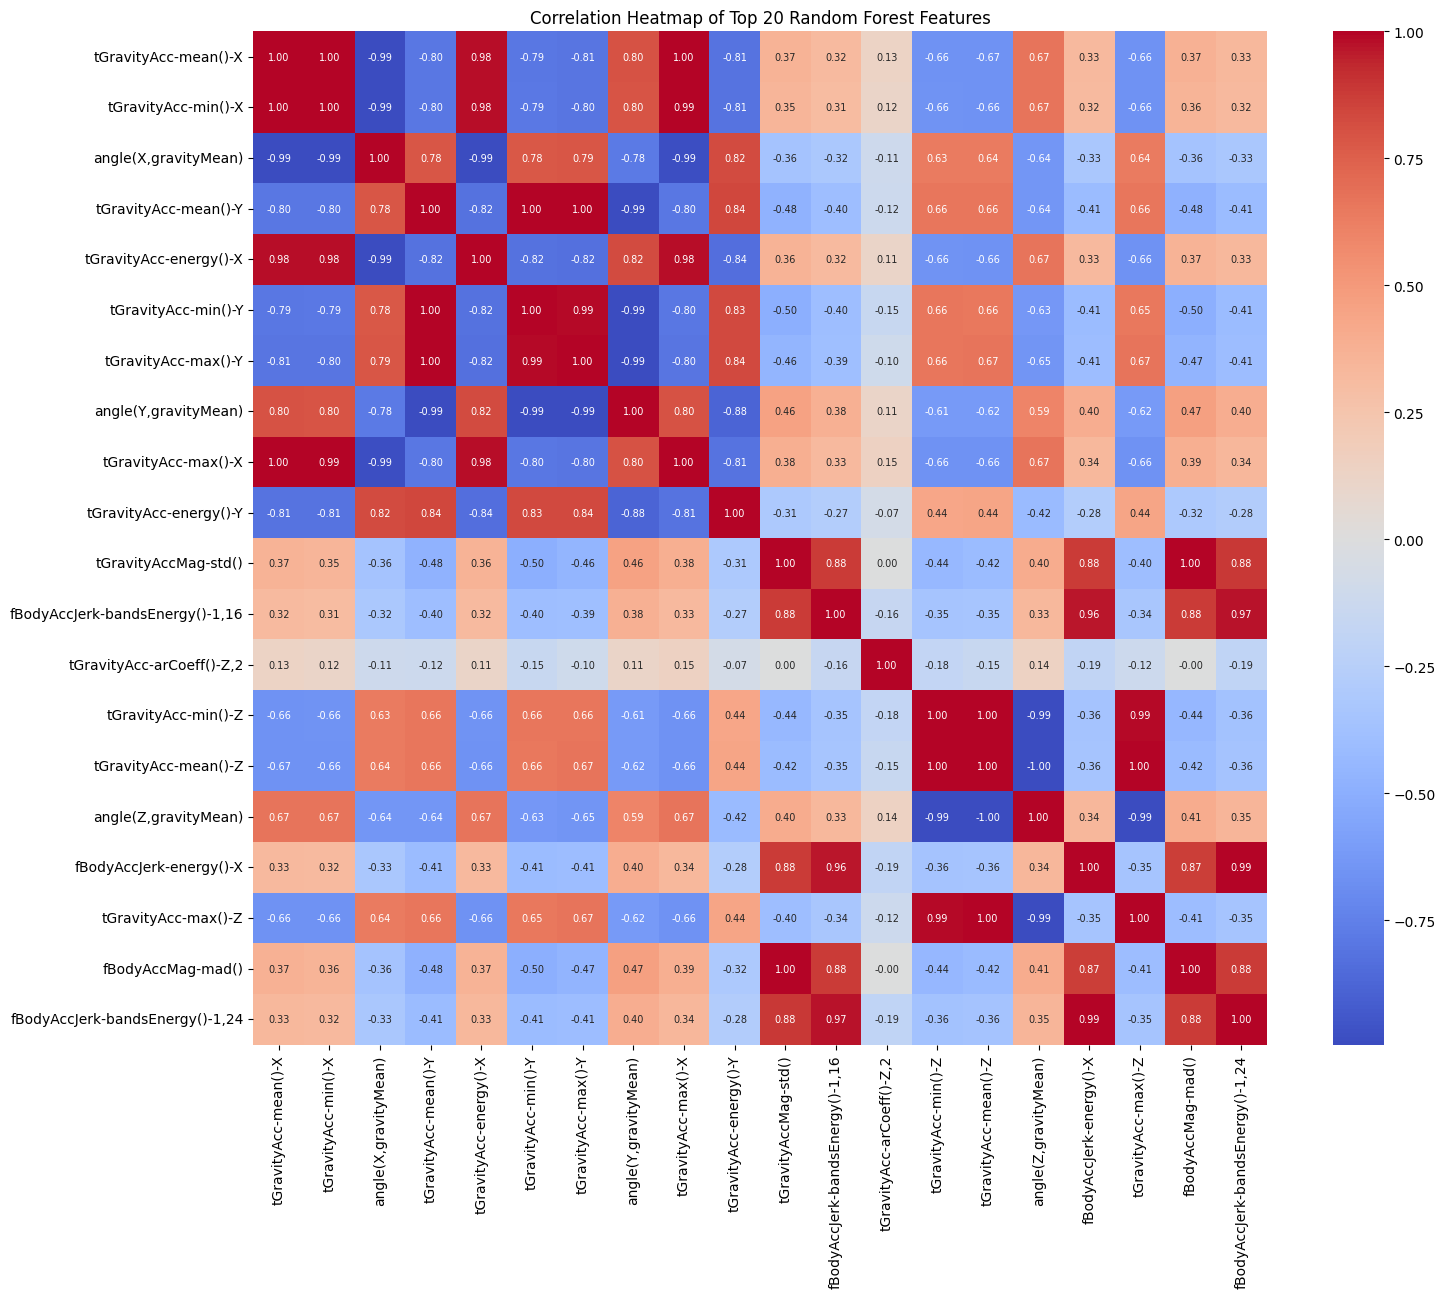

In [118]:
plt.figure(figsize=(16, 13))

sns.heatmap(
    top_20_rf_corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    annot_kws={"size": 7}
)

plt.title("Correlation Heatmap of Top 20 Random Forest Features")
plt.tight_layout()
plt.show()

In [119]:
# Count highly correlated pairs among the top 20 RF features
top_20_rf_corr_abs = top_20_rf_corr_matrix.abs()

upper_triangle_top20 = top_20_rf_corr_abs.where(
    np.triu(np.ones(top_20_rf_corr_abs.shape), k=1).astype(bool)
)

num_high_corr_top20 = (upper_triangle_top20 > 0.95).sum().sum()

print(
    f"Number of top-20 RF feature pairs with |r| > 0.95: "
    f"{num_high_corr_top20}"
)

Number of top-20 RF feature pairs with |r| > 0.95: 26


### Correlation Among Top Random Forest Features

Yes, many of the top 20 Random Forest features are also strongly correlated with each other. There are **26 feature pairs with |r| > 0.95**, and the heatmap shows several values very close to **1.00** or **-1.00**, which means some important features carry very similar information.

This suggests there is noticeable **redundancy** among the most important features. Redundancy is usually less problematic for **tree-based models** like Random Forest, because they can still choose useful splits from correlated features, but it matters more for **distance-based models** like KNN and SVM, where the same informations make learning less efficient.

### Conclusion
I would trust the model-based Random Forest importance more, because the final task is to separate all 6 activity classes, not only DYNAMIC vs. STATIC. Correlation with the binary target is useful for that simpler split, but Random Forest importance better reflects which features help the actual multiclass prediction problem.

### 5.2 XGBoost with Early Stopping

In [120]:
# Encode string activity labels into integers for XGBoost
label_encoder_xgb = LabelEncoder()

y_train_xgb_all = label_encoder_xgb.fit_transform(y_train_multi)
y_test_xgb = label_encoder_xgb.transform(y_test_multi)

In [121]:
# Hold out 15% of training data for validation
X_train_xgb_fit, X_val_xgb, y_train_xgb_fit, y_val_xgb = train_test_split(
    X_train,
    y_train_xgb_all,
    test_size=0.15,
    stratify=y_train_xgb_all, ## same proportion of class labels (categories) as the train dataset
    random_state=RANDOM_SEED
)

In [122]:
xgb_model = XGBClassifier(
    n_estimators=1000,          # builds 1000 decision trees
    learning_rate=0.01,        # small learning steps for more stable training
    max_depth=6,               # allows trees to learn moderately complex patterns
    random_state=RANDOM_SEED,  # ensures same results every run
    objective="multi:softprob",# used for multi-class classification with probabilities
    eval_metric="mlogloss",    # measures prediction error during training
    early_stopping_rounds=20   # stops training if validation loss does not improve for 20 rounds
)

In [123]:
xgb_fit_start = time.perf_counter()

xgb_model.fit(
    X_train_xgb_fit,
    y_train_xgb_fit,
    eval_set=[
        (X_train_xgb_fit, y_train_xgb_fit),
        (X_val_xgb, y_val_xgb)
    ],
    verbose=False
)

xgb_fit_time = time.perf_counter() - xgb_fit_start
print(f"XGBoost Fit Time: {xgb_fit_time:.4f} seconds")

XGBoost Fit Time: 654.2085 seconds


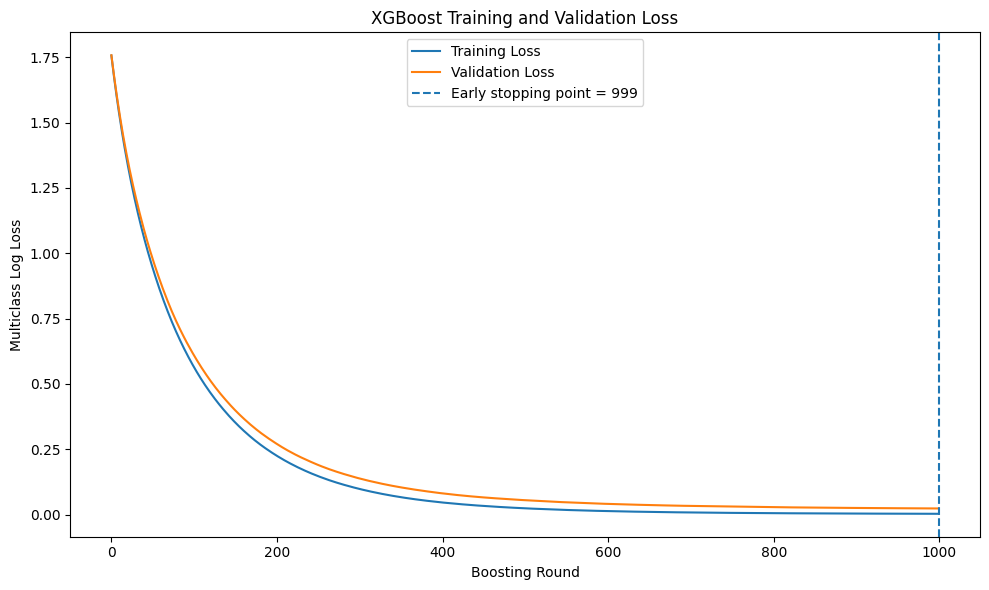

In [124]:
xgb_eval_results = xgb_model.evals_result()

train_loss = xgb_eval_results["validation_0"]["mlogloss"]
val_loss = xgb_eval_results["validation_1"]["mlogloss"]

best_round = xgb_model.best_iteration

plt.figure(figsize=(10, 6))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.axvline(
    x=best_round,
    linestyle="--",
    label=f"Early stopping point = {best_round}"
)

plt.title("XGBoost Training and Validation Loss")
plt.xlabel("Boosting Round")
plt.ylabel("Multiclass Log Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [125]:
xgb_test_pred_encoded = xgb_model.predict(X_test)
xgb_test_pred = label_encoder_xgb.inverse_transform(xgb_test_pred_encoded)

xgb_test_accuracy = accuracy_score(y_test_multi, xgb_test_pred)
xgb_test_macro_f1 = f1_score(y_test_multi, xgb_test_pred, average="macro")

print(f"XGBoost Best Iteration: {best_round}")
print(f"XGBoost Test Accuracy: {xgb_test_accuracy:.4f}")
print(f"XGBoost Test Macro F1: {xgb_test_macro_f1:.4f}")

XGBoost Best Iteration: 999
XGBoost Test Accuracy: 0.9264
XGBoost Test Macro F1: 0.9255


In [126]:
xgb_model_3000 = XGBClassifier(
    n_estimators=3000,          # builds 3000 decision trees
    learning_rate=0.01,        # small learning steps for more stable training
    max_depth=6,               # allows trees to learn moderately complex patterns
    random_state=RANDOM_SEED,  # ensures same results every run
    objective="multi:softprob",# used for multi-class classification with probabilities
    eval_metric="mlogloss",    # measures prediction error during training
    early_stopping_rounds=20   # stops training if validation loss does not improve for 20 rounds
)

In [127]:
xgb_fit_start = time.perf_counter()

xgb_model_3000.fit(
    X_train_xgb_fit,
    y_train_xgb_fit,
    eval_set=[
        (X_train_xgb_fit, y_train_xgb_fit),
        (X_val_xgb, y_val_xgb)
    ],
    verbose=False
)

xgb_fit_time = time.perf_counter() - xgb_fit_start
print(f"XGBoost 3000iter Fit Time: {xgb_fit_time:.4f} seconds")

XGBoost 3000iter Fit Time: 1260.3272 seconds


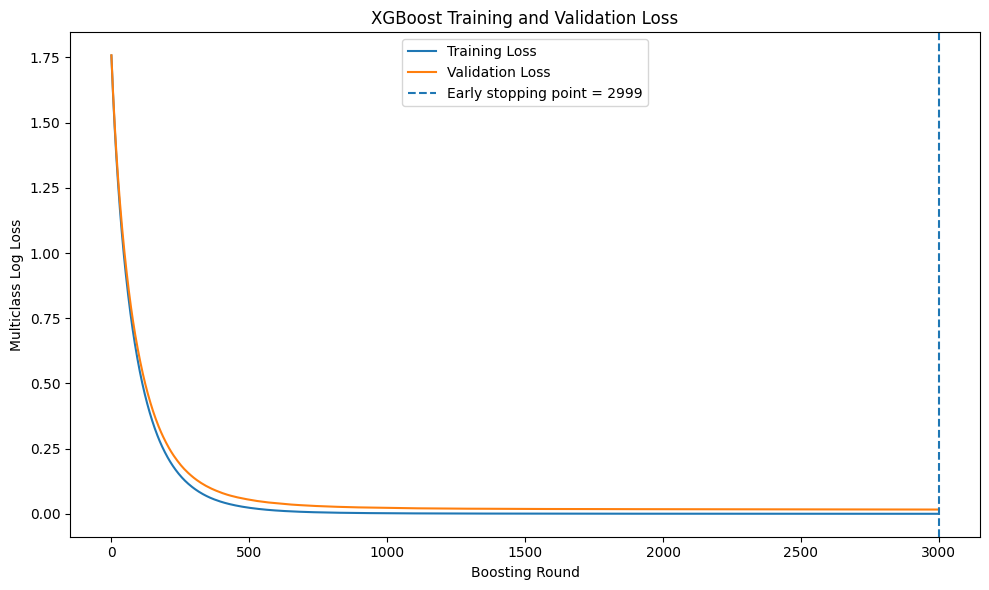

In [128]:
xgb_eval_results = xgb_model_3000.evals_result()

train_loss = xgb_eval_results["validation_0"]["mlogloss"]
val_loss = xgb_eval_results["validation_1"]["mlogloss"]

best_round = xgb_model_3000.best_iteration

plt.figure(figsize=(10, 6))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.axvline(
    x=best_round,
    linestyle="--",
    label=f"Early stopping point = {best_round}"
)

plt.title("XGBoost Training and Validation Loss")
plt.xlabel("Boosting Round")
plt.ylabel("Multiclass Log Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [129]:
xgb_test_pred_encoded = xgb_model_3000.predict(X_test)
xgb_test_pred = label_encoder_xgb.inverse_transform(xgb_test_pred_encoded)

xgb_test_accuracy = accuracy_score(y_test_multi, xgb_test_pred)
xgb_test_macro_f1 = f1_score(y_test_multi, xgb_test_pred, average="macro")

print(f"XGBoost 3000iter Best Iteration: {best_round}")
print(f"XGBoost 3000iter Test Accuracy: {xgb_test_accuracy:.4f}")
print(f"XGBoost 3000iter Test Macro F1: {xgb_test_macro_f1:.4f}")

XGBoost 3000iter Best Iteration: 2999
XGBoost 3000iter Test Accuracy: 0.9382
XGBoost 3000iter Test Macro F1: 0.9375


### XGBoost Results

With `n_estimators=1000`, early stopping was **not triggered before the maximum boosting round**, since the best iteration was **999**. I then repeated the run with `n_estimators=3000`; early stopping still did not trigger before the maximum round, and the later model achieved **93.82% accuracy** and **93.75% macro F1** on the test set.


### Mini-Batch SGD LR, binary

In [130]:
mini_batch_model = MiniBatchSGDLogisticRegression(
    learning_rate=0.01,
    n_epochs=100,
    batch_size=32,
    random_state=RANDOM_SEED
)

In [131]:
mini_batch_fit_start = time.perf_counter()
mini_batch_model.fit(X_train_sgd, y_train_binary)
mini_batch_fit_time = time.perf_counter() - mini_batch_fit_start

In [132]:
mini_batch_test_pred = mini_batch_model.predict(X_test_sgd)
mini_batch_accuracy = accuracy_score(y_test_binary, mini_batch_test_pred)
mini_batch_macro_f1 = f1_score(
    y_test_binary,
    mini_batch_test_pred,
    average="macro"
)

### Logistic Regression, 6-class

In [133]:
log_reg_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_SEED
)

In [134]:
log_reg_fit_start = time.perf_counter()
log_reg_model.fit(X_train_scaled, y_train_multi)
log_reg_fit_time = time.perf_counter() - log_reg_fit_start

In [135]:
log_reg_test_pred = log_reg_model.predict(X_test_scaled)

log_reg_accuracy = accuracy_score(y_test_multi, log_reg_test_pred)
log_reg_macro_f1 = f1_score(
    y_test_multi,
    log_reg_test_pred,
    average="macro"
)

### Refit best KNN with timing

In [136]:
best_knn_k

1

In [137]:
best_knn_model_for_table = KNeighborsClassifier(
    n_neighbors=best_knn_k
)

In [138]:
knn_fit_start = time.perf_counter()
best_knn_model_for_table.fit(X_train_scaled, y_train_multi)
knn_fit_time = time.perf_counter() - knn_fit_start

In [139]:
knn_table_pred = best_knn_model_for_table.predict(X_test_scaled)

knn_table_accuracy = accuracy_score(y_test_multi, knn_table_pred)
knn_table_macro_f1 = f1_score(
    y_test_multi,
    knn_table_pred,
    average="macro"
)

### Refit best LinearSVC with timing

In [140]:
best_svm_c

np.float64(0.1)

In [141]:
best_svm_model_for_table = LinearSVC(
    C=best_svm_c,
    max_iter=20000,
    random_state=RANDOM_SEED
)

In [142]:
svm_fit_start = time.perf_counter()
best_svm_model_for_table.fit(X_train_scaled, y_train_multi)
svm_fit_time = time.perf_counter() - svm_fit_start

In [143]:
svm_table_pred = best_svm_model_for_table.predict(X_test_scaled)

svm_table_accuracy = accuracy_score(y_test_multi, svm_table_pred)
svm_table_macro_f1 = f1_score(
    y_test_multi,
    svm_table_pred,
    average="macro"
)

### Refit best Decision Tree with timing

In [144]:
best_tree_depth_value = (
    None if str(best_tree_depth) == "None"
    else int(best_tree_depth)
)

In [145]:
best_tree_depth_value

10

In [146]:
best_tree_model_for_table = DecisionTreeClassifier(
    max_depth=best_tree_depth_value,
    random_state=RANDOM_SEED
)

In [147]:
tree_fit_start = time.perf_counter()
best_tree_model_for_table.fit(X_train, y_train_multi)
tree_fit_time = time.perf_counter() - tree_fit_start

In [148]:
tree_table_pred = best_tree_model_for_table.predict(X_test)

tree_table_accuracy = accuracy_score(y_test_multi, tree_table_pred)
tree_table_macro_f1 = f1_score(
    y_test_multi,
    tree_table_pred,
    average="macro"
)

### 5.3 - Model Comparison Table

In [149]:
model_comparison_df = pd.DataFrame([
    {
        "Model": "Mini-Batch SGD LR (my implementation, binary)",
        "Accuracy": mini_batch_accuracy,
        "Macro F1": mini_batch_macro_f1,
        "Fit time (s)": mini_batch_fit_time
    },
    {
        "Model": "Logistic Regression (sklearn, 6-class)",
        "Accuracy": log_reg_accuracy,
        "Macro F1": log_reg_macro_f1,
        "Fit time (s)": log_reg_fit_time
    },
    {
        "Model": "KNN (best k)",
        "Accuracy": knn_table_accuracy,
        "Macro F1": knn_table_macro_f1,
        "Fit time (s)": knn_fit_time
    },
    {
        "Model": "LinearSVC (best C)",
        "Accuracy": svm_table_accuracy,
        "Macro F1": svm_table_macro_f1,
        "Fit time (s)": svm_fit_time
    },
    {
        "Model": "Decision Tree (best depth)",
        "Accuracy": tree_table_accuracy,
        "Macro F1": tree_table_macro_f1,
        "Fit time (s)": tree_fit_time
    },
    {
        "Model": "Random Forest (tuned)",
        "Accuracy": rf_test_accuracy,
        "Macro F1": rf_test_macro_f1,
        "Fit time (s)": rf_fit_time
    },
    {
        "Model": "XGBoost",
        "Accuracy": xgb_test_accuracy,
        "Macro F1": xgb_test_macro_f1,
        "Fit time (s)": xgb_fit_time
    }
])

model_comparison_df = model_comparison_df.sort_values(
    by="Macro F1",
    ascending=False
)
model_comparison_df

,Model,Accuracy,Macro F1,Fit time (s)
0,"Mini-Batch SGD LR (my implementation, binary)",0.999661,0.999660,7.084902
3,LinearSVC (best C),0.961995,0.962914,6.786906
1,"Logistic Regression (sklearn, 6-class)",0.954530,0.954374,20.321090
6,XGBoost,0.938242,0.937474,1260.327197
5,Random Forest (tuned),0.928741,0.927072,38.786175
4,Decision Tree (best depth),0.862572,0.859044,4.911865
2,KNN (best k),0.853410,0.850884,0.051787


### Model Comparison Conclusion

The custom Mini-Batch SGD Logistic Regression has the highest score, but it solves an easier **binary** task, so among the comparable **6-class** models, **LinearSVC wins** with **96.20% accuracy** and **96.29% macro F1**. The best ensemble model, **XGBoost**, performs worse than both LinearSVC and Logistic Regression while taking much longer to train, so its added complexity and execution time are **not justified** in this case.


In [150]:
# 5-fold stratified cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_SEED
)

scoring_metrics = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro"
}

In [151]:
cv_models = {
    "LinearSVC": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearSVC(
            C=best_svm_c,
            max_iter=20000,
            random_state=RANDOM_SEED
        ))
    ]),
    
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_SEED
        ))
    ])
}

In [152]:
cv_summary_results = []

for model_name, model in cv_models.items():
    cv_results = cross_validate(
        model,
        X_train,
        y_train_multi,
        cv=cv_strategy,
        scoring=scoring_metrics,
    )
    
    cv_summary_results.append({
        "Model": model_name,
        "Accuracy Mean": cv_results["test_accuracy"].mean(),
        "Accuracy Std": cv_results["test_accuracy"].std(),
        "Macro F1 Mean": cv_results["test_macro_f1"].mean(),
        "Macro F1 Std": cv_results["test_macro_f1"].std()
    })

pd.DataFrame(cv_summary_results)

,Model,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,LinearSVC,0.985038,0.003965,0.986073,0.003668
1,Logistic Regression,0.984766,0.003293,0.985808,0.002998


In [153]:
xgb_cv_model = XGBClassifier(
    n_estimators=3000,
    learning_rate=0.01,
    max_depth=6,
    random_state=RANDOM_SEED,
    objective="multi:softprob",
    eval_metric="mlogloss",
    n_jobs=-1
)

xgb_cv_results = cross_validate(
    xgb_cv_model,
    X_train,
    y_train_xgb_all,
    cv=cv_strategy,
    scoring=scoring_metrics,
)

cv_summary_results.append({
    "Model": "XGBoost",
    "Accuracy Mean": xgb_cv_results["test_accuracy"].mean(),
    "Accuracy Std": xgb_cv_results["test_accuracy"].std(),
    "Macro F1 Mean": xgb_cv_results["test_macro_f1"].mean(),
    "Macro F1 Std": xgb_cv_results["test_macro_f1"].std()
})

cv_summary_df = pd.DataFrame(cv_summary_results)
cv_summary_df

,Model,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,LinearSVC,0.985038,0.003965,0.986073,0.003668
1,Logistic Regression,0.984766,0.003293,0.985808,0.002998
2,XGBoost,0.991703,0.001319,0.991841,0.001310


In [154]:
formatted_cv_summary_df = cv_summary_df.copy()

formatted_cv_summary_df["Accuracy"] = formatted_cv_summary_df.apply(
    lambda row: f"{row['Accuracy Mean']:.4f} ± {row['Accuracy Std']:.4f}",
    axis=1
)

formatted_cv_summary_df["Macro F1"] = formatted_cv_summary_df.apply(
    lambda row: f"{row['Macro F1 Mean']:.4f} ± {row['Macro F1 Std']:.4f}",
    axis=1
)

formatted_cv_summary_df = formatted_cv_summary_df[
    ["Model", "Accuracy", "Macro F1"]
]

formatted_cv_summary_df

,Model,Accuracy,Macro F1
0,LinearSVC,0.9850 ± 0.0040,0.9861 ± 0.0037
1,Logistic Regression,0.9848 ± 0.0033,0.9858 ± 0.0030
2,XGBoost,0.9917 ± 0.0013,0.9918 ± 0.0013


### Cross-Validation Results

From the cross-validation results, all three models perform very well and the differences between `LinearSVC` and Logistic Regression are very small. `LinearSVC` has a slightly higher mean accuracy and macro F1 than Logistic Regression, but the difference is almost negligible, so both models generalize very similarly on this dataset.

The best cross-validation result is achieved by **XGBoost**, with **99.17% mean accuracy** and **99.18% mean macro F1**. It also has the lowest standard deviation, which means its performance is very stable across the folds. Based only on cross-validation performance, **XGBoost is the strongest model among these three**, although training time should also be considered when choosing the final model.

### Stability vs. Higher Mean Performance

In a deployed system, I would usually prefer the model with **0.94 ± 0.001** because its performance is much more stable and predictable across different data points. The model with **0.96 ± 0.02** has a better average score, but the larger variation means it may behave worse on new data.

### Part 2 — Cross-validation strategy
Standard `StratifiedKFold` is problematic here because it preserves class proportions but does not keep each subject entirely inside one fold, so the same subject may appear in both training and validation data.

In [155]:
groups = train_df["subject"]
group_cv = GroupKFold(n_splits=5)

In [156]:
best_group_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearSVC(
        C=best_svm_c,
        max_iter=20000,
        random_state=RANDOM_SEED
    ))
])

In [157]:
group_cv_results = cross_validate(
    best_group_model,
    X_train,
    y_train_multi,
    groups=groups,
    cv=group_cv,
    scoring="accuracy",
)

In [158]:
group_accuracy_mean = group_cv_results["test_score"].mean()
group_accuracy_std = group_cv_results["test_score"].std()
print(
    f"GroupKFold Accuracy: "
    f"{group_accuracy_mean:.4f} ± {group_accuracy_std:.4f}"
)

GroupKFold Accuracy: 0.9377 ± 0.0337


In [159]:
best_group_xgb_model = XGBClassifier(
    n_estimators=3000,
    learning_rate=0.01,
    max_depth=6,
    random_state=RANDOM_SEED,
    objective="multi:softprob",
    eval_metric="mlogloss",
)

In [160]:
group_xgb_cv_results = cross_validate(
    best_group_xgb_model,
    X_train,
    y_train_xgb_all,
    groups=groups,
    cv=group_cv,
    scoring="accuracy",
)

In [161]:
group_xgb_accuracy_mean = group_xgb_cv_results["test_score"].mean()
group_xgb_accuracy_std = group_xgb_cv_results["test_score"].std()
print(
    f"GroupKFold XGBoost Accuracy: "
    f"{group_xgb_accuracy_mean:.4f} ± {group_xgb_accuracy_std:.4f}"
)

GroupKFold XGBoost Accuracy: 0.9344 ± 0.0339


### Conclusion
Using `GroupKFold`, the best model achieved **0.9377 ± 0.0337 accuracy**. This is noticeably lower than the earlier `StratifiedKFold` result of **0.9850 ± 0.0040**, which shows that evaluation becomes harder when the model must generalize to completely unseen subjects.

`GroupKFold` gives the more honest estimate of real-world performance because it prevents the same person's movement patterns from appearing in both training and validation folds.

### 6.2 - Per-Class Performance

In [162]:
best_overall_model = xgb_model_3000


In [163]:
# Use the already trained best overall model
y_test_best_pred_encoded = best_overall_model.predict(X_test)
y_test_best_pred = label_encoder_xgb.inverse_transform(
    y_test_best_pred_encoded.astype(int)
)

y_test_best_proba = pd.DataFrame(
    best_overall_model.predict_proba(X_test),
    columns=label_encoder_xgb.classes_,
    index=X_test.index
)[activity_labels].to_numpy()

In [164]:
report_dict = classification_report(
    y_test_multi,
    y_test_best_pred,
    labels=activity_labels,
    output_dict=True,
    digits=4
)

print(
    classification_report(
        y_test_multi,
        y_test_best_pred,
        labels=activity_labels,
        digits=4
    )
)

                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       537
           SITTING     0.9317    0.8615    0.8952       491
          STANDING     0.8836    0.9417    0.9117       532
           WALKING     0.9190    0.9839    0.9503       496
WALKING_DOWNSTAIRS     0.9722    0.9167    0.9436       420
  WALKING_UPSTAIRS     0.9329    0.9151    0.9239       471

          accuracy                         0.9382      2947
         macro avg     0.9399    0.9365    0.9375      2947
      weighted avg     0.9393    0.9382    0.9381      2947



In [165]:
per_class_report_df = pd.DataFrame(report_dict).T.loc[activity_labels]
per_class_report_df

,precision,recall,f1-score,support
LAYING,1.000000,1.000000,1.000000,537.0
SITTING,0.931718,0.861507,0.895238,491.0
STANDING,0.883598,0.941729,0.911738,532.0
WALKING,0.919021,0.983871,0.950341,496.0
WALKING_DOWNSTAIRS,0.972222,0.916667,0.943627,420.0
WALKING_UPSTAIRS,0.932900,0.915074,0.923901,471.0


In [166]:
lowest_recall_class = per_class_report_df["recall"].idxmin()
lowest_precision_class = per_class_report_df["precision"].idxmin()

print(f"Lowest recall class: {lowest_recall_class}")
print(f"Lowest precision class: {lowest_precision_class}")
print(f"Are they the same class? {lowest_recall_class == lowest_precision_class}")

Lowest recall class: SITTING
Lowest precision class: STANDING
Are they the same class? False


In [167]:
# One-vs-rest binarized labels
y_test_binarized = label_binarize(
    y_test_multi,
    classes=activity_labels
)

# Predicted probabilities from XGBoost
decision_scores = y_test_best_proba

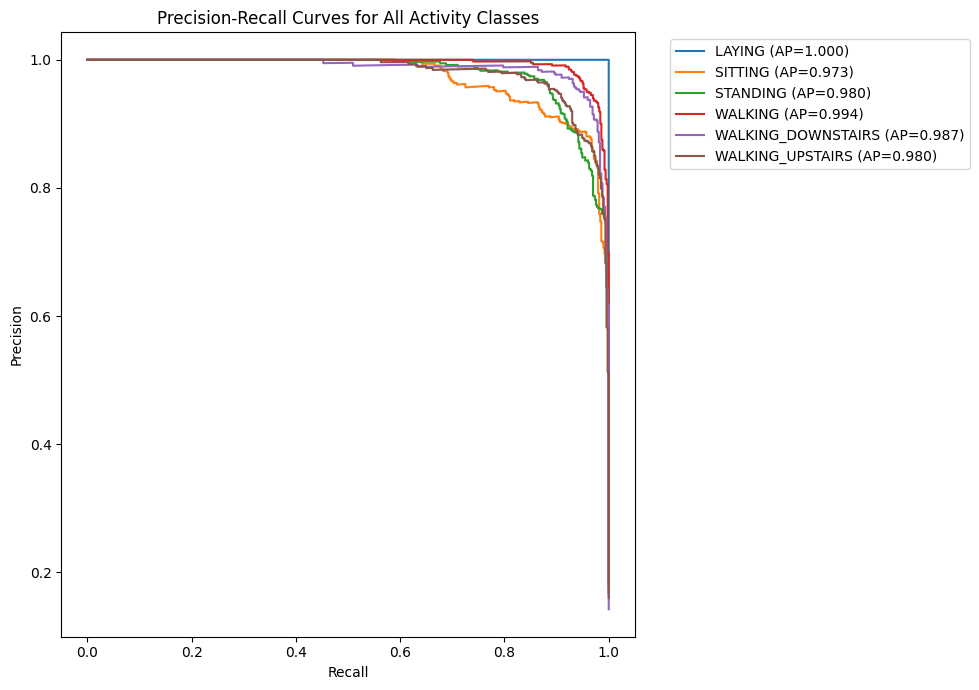

In [168]:
plt.figure(figsize=(10, 7))

for i, activity in enumerate(activity_labels):
    precision, recall, _ = precision_recall_curve(
        y_test_binarized[:, i],
        decision_scores[:, i]
    )
    
    avg_precision = average_precision_score(
        y_test_binarized[:, i],
        decision_scores[:, i]
    )
    
    plt.plot(
        recall,
        precision,
        label=f"{activity} (AP={avg_precision:.3f})"
    )

plt.title("Precision-Recall Curves for All Activity Classes")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Conclusion for this topic

The printed results above show that for the XGBoost model, the class with the lowest recall is **`SITTING`**, with a recall of **86.15%**. This means that the model misses some true `SITTING` samples and classifies them as another activity.

The class with the lowest precision is **`STANDING`**, with a precision of **88.36%**. This means that when the model predicts `STANDING`, it is slightly less reliable compared to the other classes, because some samples from other activities are incorrectly predicted as `STANDING`.

Since the lowest recall class and the lowest precision class are not the same, the model is making two different kinds of mistakes. It misses `SITTING` more often, while `STANDING` receives more incorrect predictions from other classes. This again matches the earlier confusion matrix analysis, where `SITTING` and `STANDING` were the most difficult activities to separate.

### 6.3 - Confusion Matrix Analysis

In [169]:
best_model_cm = confusion_matrix(
    y_test_multi,
    y_test_best_pred,
    labels=activity_labels,
    normalize="true"
)

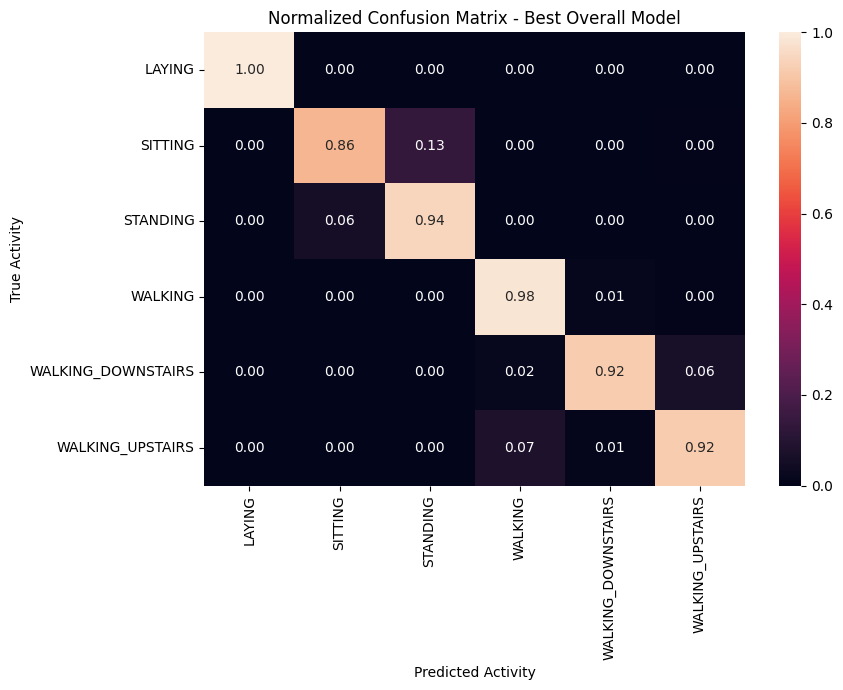

In [170]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    best_model_cm,
    annot=True,
    fmt=".2f",
    xticklabels=activity_labels,
    yticklabels=activity_labels
)

plt.title("Normalized Confusion Matrix - Best Overall Model")
plt.xlabel("Predicted Activity")
plt.ylabel("True Activity")
plt.tight_layout()
plt.show()

In [171]:
confused_pairs = []

for i in range(len(activity_labels)):
    for j in range(i + 1, len(activity_labels)):
        combined_confusion = best_model_cm[i, j] + best_model_cm[j, i]
        
        confused_pairs.append({
            "Activity Pair": f"{activity_labels[i]} ↔ {activity_labels[j]}",
            "Combined Normalized Confusion": combined_confusion
        })

most_confused_pairs_df = pd.DataFrame(confused_pairs).sort_values(
    by="Combined Normalized Confusion",
    ascending=False
)

most_confused_pairs_df.head(2)

,Activity Pair,Combined Normalized Confusion
5,SITTING ↔ STANDING,0.192690
13,WALKING ↔ WALKING_UPSTAIRS,0.078342


### Conclusion

The table above identifies the two most-confused activity pairs for the XGBoost model. The most confused pair is **`SITTING` ↔ `STANDING`**, with a combined normalized confusion of **0.193**. This makes sense because both activities are static postures and can produce very similar phone sensor patterns, especially in features where movement is low, such as `fBodyGyro-energy()-Y` and `tBodyGyroJerkMag-mean()`.

The second most confused pair is **`WALKING` ↔ `WALKING_UPSTAIRS`**, with a combined normalized confusion of **0.078**. These activities are also similar because both include repeated walking movement, so the model can sometimes confuse normal walking with walking upstairs.

Overall, XGBoost performs very well, but the remaining errors are mostly between activities that are naturally similar. Gravity features such as `tGravityAcc-mean()-Z` help separate the classes, but they do not fully remove the overlap between similar activities.

### 6.4 - Subject-Level Generalization

In [172]:
subject_accuracy_df = pd.DataFrame({
    "subject": test_df["subject"].values,
    "y_true": y_test_multi.values,
    "y_pred": y_test_best_pred
})

In [173]:
per_subject_accuracy = (
    subject_accuracy_df
    .groupby("subject")
    .apply(
        lambda group: accuracy_score(group["y_true"], group["y_pred"]),
        include_groups=False
    )
    .reset_index(name="accuracy")
)

per_subject_accuracy

,subject,accuracy
0,2,0.930464
1,4,0.968454
2,9,0.871528
3,10,0.806122
4,12,0.959375
5,13,0.978593
6,18,0.931319
7,20,0.971751
8,24,0.994751


In [174]:
print(f"Mean subject accuracy: {per_subject_accuracy['accuracy'].mean():.4f}")
print(f"Std subject accuracy: {per_subject_accuracy['accuracy'].std():.4f}")
print(f"Lowest subject accuracy: {per_subject_accuracy['accuracy'].min():.4f}")
print(f"Highest subject accuracy: {per_subject_accuracy['accuracy'].max():.4f}")

Mean subject accuracy: 0.9347
Std subject accuracy: 0.0604
Lowest subject accuracy: 0.8061
Highest subject accuracy: 0.9948


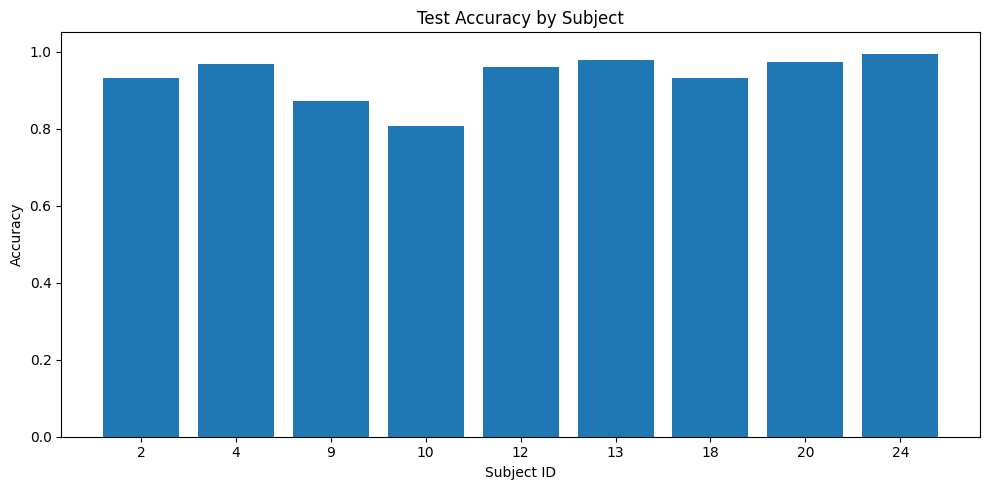

In [175]:
# Plot per-subject accuracy

plt.figure(figsize=(10, 5))

plt.bar(
    per_subject_accuracy["subject"].astype(str),
    per_subject_accuracy["accuracy"]
)

plt.title("Test Accuracy by Subject")
plt.xlabel("Subject ID")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

### Conclusion

Performance is generally strong across subjects, with a **mean accuracy of 93.47%**, but it is not perfectly consistent. Accuracy ranges from **80.61%** for subject 10 to **99.48%** for subject 24, with a standard deviation of **6.04 percentage points**. This suggests that the model generalizes well overall, but some users are harder to classify than others.

Subject 10 has the weakest result compared to the other subjects, which means that this subject probably has movement patterns, phone position, or body orientation that are less similar to the training data. On the other hand, subject 24 is classified almost perfectly.

This difference between subjects is important for real-world usage because the model may work very well for some people, but noticeably worse for others. Because of that, subject-level evaluation is useful for checking whether the model is truly robust across different users, not only accurate on average.

## Model Card: Best Activity Classifier

### Model summary
The best classifier was **LinearSVC** with tuned hyperparameter **C = 0.1**. The model was trained on the full 6-class activity task using the 561 engineered sensor features, with data scaled by **StandardScaler**.

### Performance
On the test set, the model achieved **96.20% accuracy** and **96.29% macro F1-score**. The worst-performing class was **SITTING**, with an F1-score of **0.9132**, mainly because it was sometimes confused with **STANDING**.

### Limitations
First, the model was evaluated on a controlled benchmark dataset collected with a waist-mounted smartphone, so performance may drop with different phone positions or real-world usage patterns. Second, some similar activities remain difficult to separate, especially **SITTING vs. STANDING** and, in fewer cases , **WALKING vs. WALKING_UPSTAIRS**.

### Ethical considerations
A real activity-monitoring product could create privacy concerns, because continuous motion tracking may reveal sensitive daily routines and behavior patterns if collected or stored without clear user consent.


### XGBoost Partial Dependence Plots

In [176]:
top_5_rf_features = (
    rf_feature_importances
    .sort_values("Importance", ascending=False)
    .head(5)["Feature"]
    .tolist()
)


In [177]:
top_5_rf_features


['tGravityAcc-mean()-X',
 'tGravityAcc-min()-X',
 'angle(X,gravityMean)',
 'tGravityAcc-mean()-Y',
 'tGravityAcc-energy()-X']

In [178]:
top_2_rf_features = top_5_rf_features[:2]

# Hardest class from Task 6.2: lowest per-class F1
hardest_class = per_class_report_df["f1-score"].idxmin()

xgb_classes = label_encoder_xgb.classes_
xgb_hardest_class_index = label_encoder_xgb.transform([hardest_class])[0]

print("Top 5 RF features:", top_5_rf_features)
print("Top 2 RF features:", top_2_rf_features)
print("Hardest class:", hardest_class)
print("Hardest class index for XGBoost:", xgb_hardest_class_index)


Top 5 RF features: ['tGravityAcc-mean()-X', 'tGravityAcc-min()-X', 'angle(X,gravityMean)', 'tGravityAcc-mean()-Y', 'tGravityAcc-energy()-X']
Top 2 RF features: ['tGravityAcc-mean()-X', 'tGravityAcc-min()-X']
Hardest class: SITTING
Hardest class index for XGBoost: 1


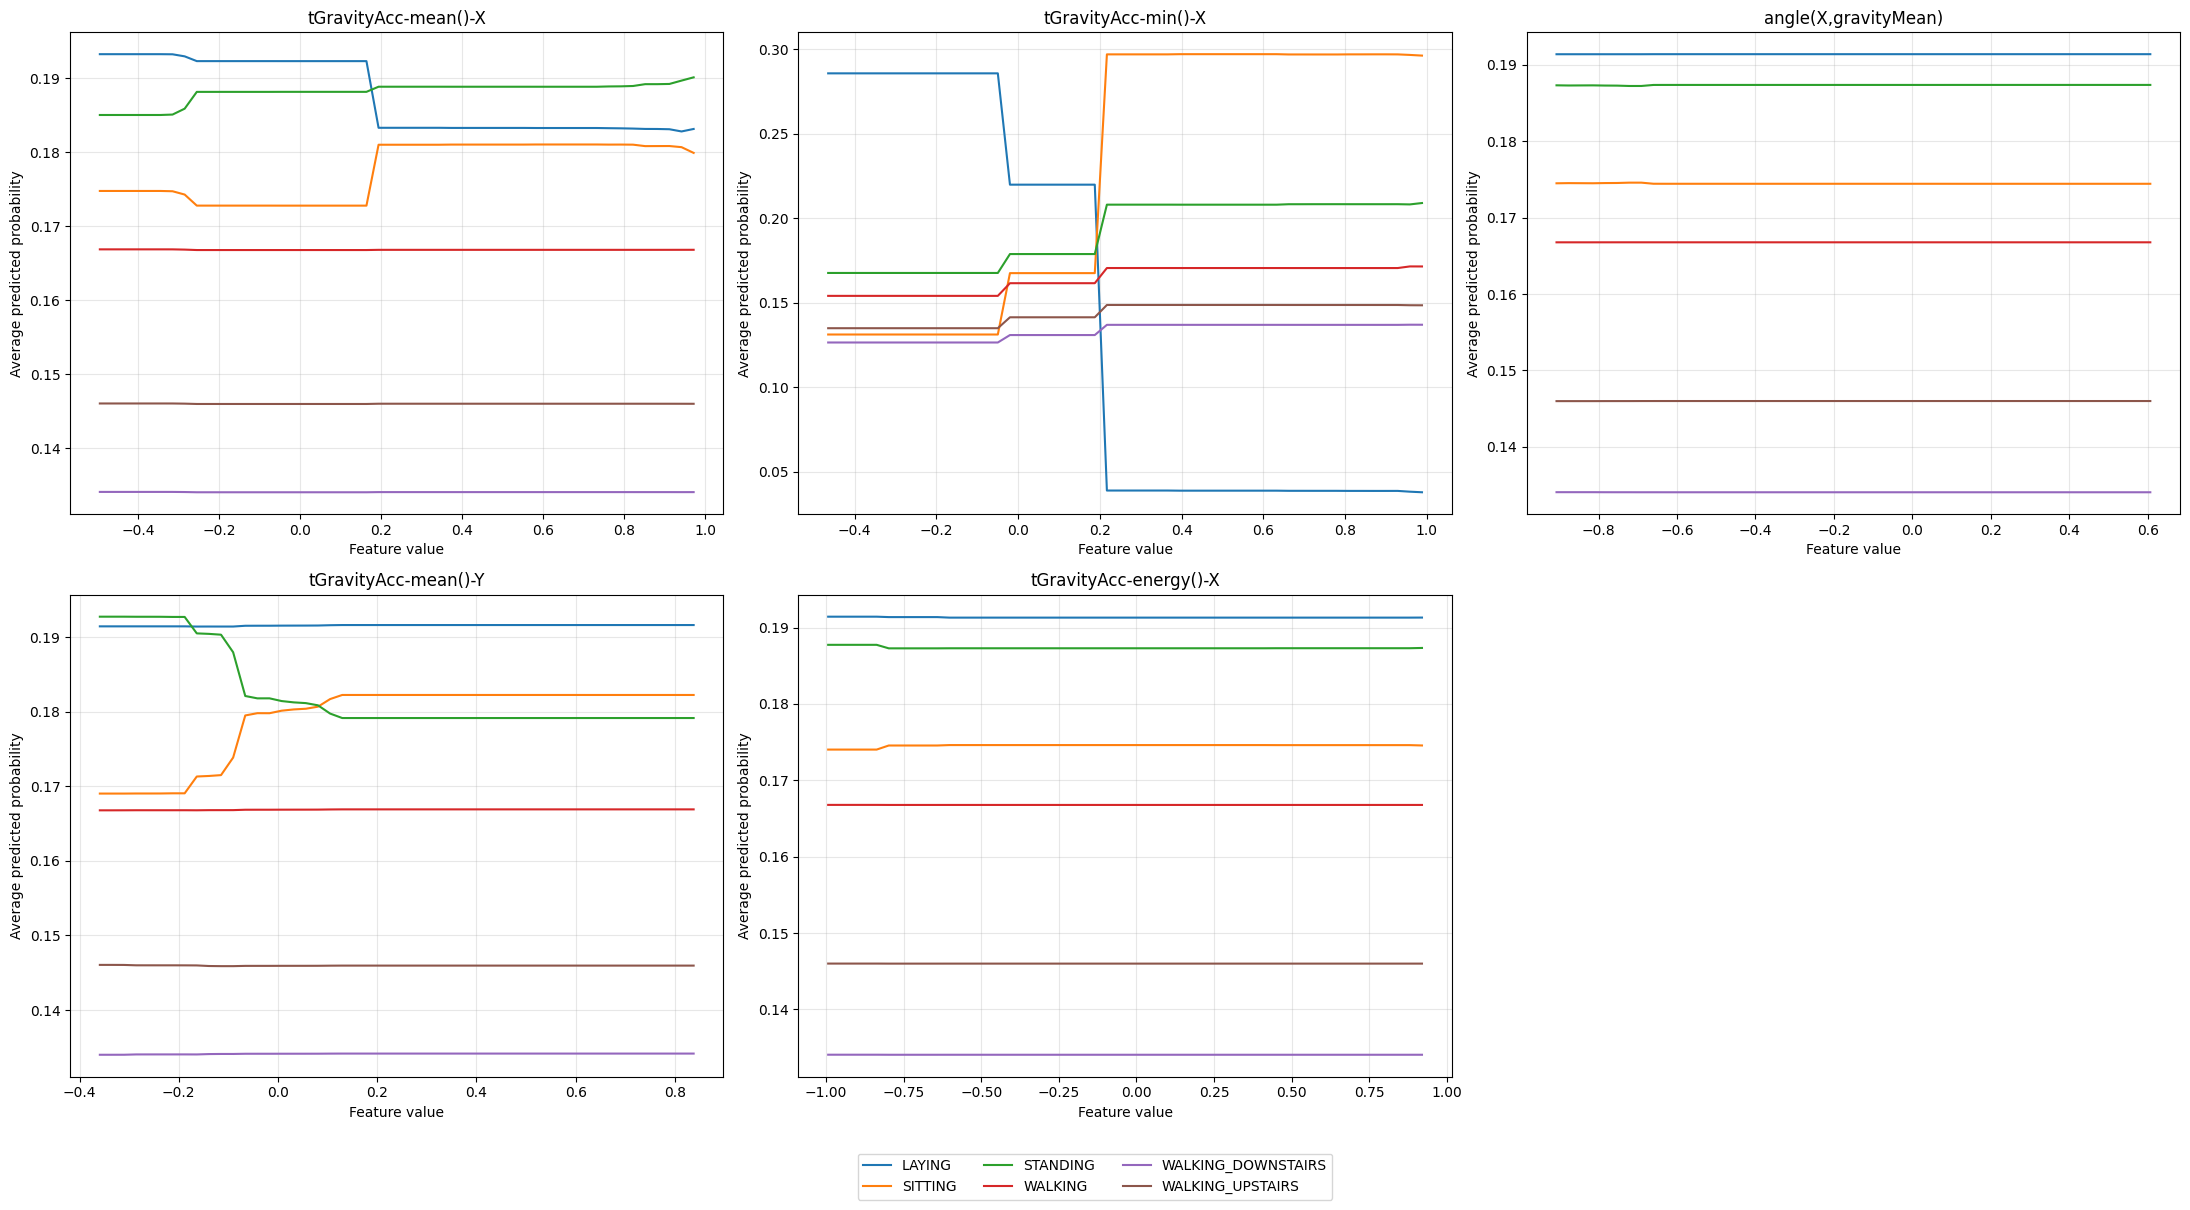

In [179]:
fig, axes = plt.subplots(2, 3, figsize=(22, 12))
axes = axes.ravel()

for ax, feature in zip(axes, top_5_rf_features):
    pd_result = partial_dependence(
        estimator=best_overall_model,
        X=X_train,
        features=[feature],
        kind="average",
        response_method="predict_proba",
        method="brute",
        grid_resolution=50
    )

    grid_values = pd_result["grid_values"][0]
    average_predictions = pd_result["average"]

    for class_idx, class_name in enumerate(xgb_classes):
        ax.plot(
            grid_values,
            average_predictions[class_idx],
            label=class_name
        )

    ax.set_title(feature)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Average predicted probability")
    ax.grid(alpha=0.3)

# Remove unused 6th subplot
axes[-1].axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, -0.01)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


In [180]:
xgb_pdp_change_rows = []

for feature in top_5_rf_features:
    pd_result = partial_dependence(
        estimator=best_overall_model,
        X=X_train,
        features=[feature],
        kind="average",
        response_method="predict_proba",
        method="brute",
        grid_resolution=50
    )

    average_predictions = pd_result["average"]

    for class_idx, class_name in enumerate(xgb_classes):
        start_prob = average_predictions[class_idx][0]
        end_prob = average_predictions[class_idx][-1]
        delta = end_prob - start_prob

        xgb_pdp_change_rows.append({
            "Feature": feature,
            "Class": class_name,
            "Probability Change": delta,
            "Absolute Change": abs(delta)
        })

xgb_pdp_change_df = pd.DataFrame(xgb_pdp_change_rows)

xgb_largest_change_per_feature = (
    xgb_pdp_change_df
    .sort_values("Absolute Change", ascending=False)
    .groupby("Feature", as_index=False)
    .head(1)
    .sort_values("Absolute Change", ascending=False)
)

xgb_largest_change_per_feature


,Feature,Class,Probability Change,Absolute Change
6,tGravityAcc-min()-X,LAYING,-0.247817,0.247817
20,tGravityAcc-mean()-Y,STANDING,-0.013581,0.013581
0,tGravityAcc-mean()-X,LAYING,-0.010098,0.010098
25,tGravityAcc-energy()-X,SITTING,0.000539,0.000539
13,"angle(X,gravityMean)",SITTING,-0.000064,0.000064


### 1D PDP Interpretation

For `tGravityAcc-mean()-X`, increasing the feature value slightly decreases the predicted probability of `LAYING`. The change is not very large, but it shows that this feature still has some effect on the posture classes.

For `tGravityAcc-min()-X`, increasing the feature value strongly decreases the predicted probability of `LAYING`. This is the strongest effect from the analyzed features, with a probability change of about **0.248**. This means that XGBoost uses this feature a lot when separating `LAYING` from the other activities.

For `angle(X,gravityMean)`, the predicted probabilities are almost flat. This means that changing this feature does not strongly affect the model prediction for the selected class, so it is not very important in this PDP analysis.

For `tGravityAcc-mean()-Y`, increasing the feature value decreases the predicted probability of `STANDING`. At the same time, the model gives more probability to similar static classes such as `SITTING`, which makes sense because these classes are also the most confused.

For `tGravityAcc-energy()-X`, the probability change is very small. This means that this feature does not have a strong individual effect on the XGBoost prediction in this analysis.


### XGBoost 2D Partial Dependence Plot


In [181]:
best_overall_model


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",20
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fro

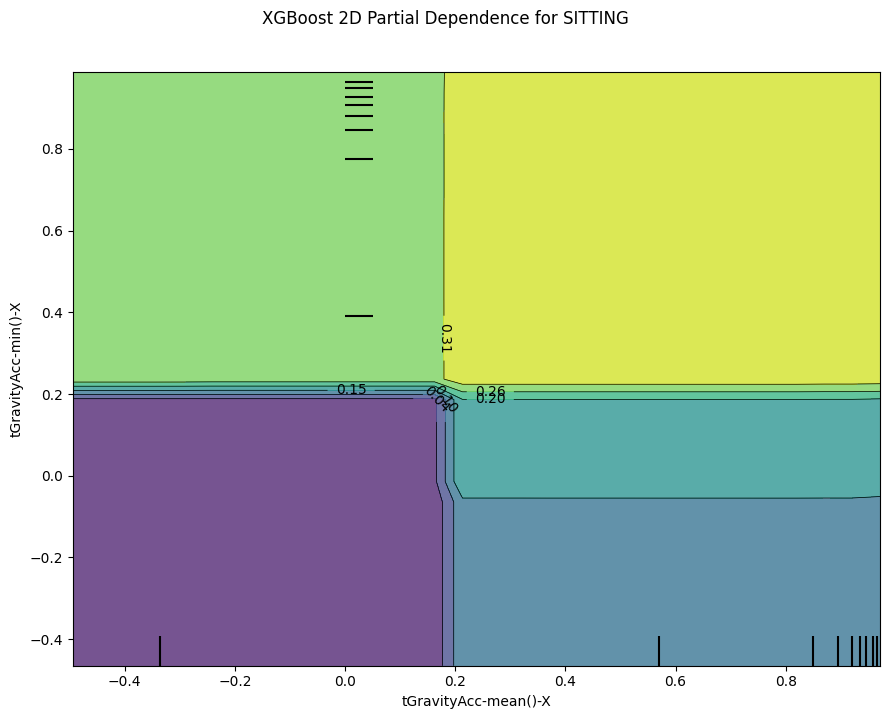

In [182]:
fig, ax = plt.subplots(figsize=(9, 7))

PartialDependenceDisplay.from_estimator(
    estimator=best_overall_model,
    X=X_train,
    features=[tuple(top_2_rf_features)],
    target=xgb_hardest_class_index,
    kind="average",
    response_method="predict_proba",
    method="brute",
    grid_resolution=30,
    ax=ax
)

plt.suptitle(
    f"XGBoost 2D Partial Dependence for {hardest_class}",
    y=1.02
)

plt.tight_layout()
plt.show()


### 2D Partial Dependence Interpretation for SITTING

The 2D PDP shows that the model gives the highest probability to `SITTING` when both `tGravityAcc-mean()-X` and `tGravityAcc-min()-X` are relatively high. The probability is lower when both features have smaller values.

This suggests that XGBoost is not only looking at one feature separately, but also uses the combination of these two gravity-based features. When both features are high together, the model becomes more confident that the activity is `SITTING`.

### Conclusion

The PDP analysis shows that `tGravityAcc-min()-X` has the strongest effect among the analyzed features, especially for reducing the probability of `LAYING`. Other features such as `tGravityAcc-mean()-X` and `tGravityAcc-mean()-Y` also affect the predictions, but their effect is smaller.

For `SITTING`, the 2D PDP shows that the model gives higher probability when both `tGravityAcc-mean()-X` and `tGravityAcc-min()-X` are high. This helps explain why `SITTING` and `STANDING` are still confused in the confusion matrix, because they depend on similar gravity-based posture features.

Overall, XGBoost uses gravity features to separate static activities, but there is still overlap between similar postures like `SITTING` and `STANDING`.